# Notebook 33 — Fine-grain image → stage evaluation (BBCH case study)

Notebook 32 answers *"can the model find the right stage at all?"* with aggregate
R@1 / R@3 / MRR. This notebook answers *"how wrong is it, and in which direction?"*:

1. **Per-stage confusion** — which stages get predicted instead of the truth, and how
   scattered each ground-truth row of the confusion matrix is.
2. **Ordinal distance** — every stage sits on the BBCH-general 0–99 phenology axis; how
   far (in BBCH units) is the top-1 prediction from the ground truth? The axis is treated
   as linear: `97 → 05` is 92 units, `03 → 95` is 92 units.
3. **Principal / secondary consistency** — does the secondary-level prediction belong to
   the same principal stage as the photo?

## Scope of this run

Only SigLIP2 with **mean-pooled text** is kept: the raw encoder
(`26_zs_siglip2_meanpool`) and its fine-tuned versions with 0 / 2 / 4 / 8 unfrozen
blocks (`27D_last_*`). The chunk-max (27C) and truncate variants are dropped, so the
SigLIP2 comparison holds text pooling fixed.

All DINOv3+BGE experiments are kept: the out-of-box encoder (`zz_dinov3_bge_raw`), the
0/2/4/6/8-block layer sweep (`27_last_*`), the training-size sweep (`smaller_size_*`,
6 blocks) and the negative-mining sweep (`29_sweep_size_*`, 6 blocks). CLIP mean-pool,
CLIP truncate and the random control are kept only as out-of-box references in group
(a); they are not part of the SigLIP2 or DINOv3+BGE family sweeps. The scored set is
therefore 30 checkpoints.

Figures use publication labels of the form
`[architecture]_[unfrozen blocks]_[train size]` (`SigLIP2-meanpool_4L_2500`,
`DINOv3-BGE-mined_6L_5000`, …); raw encoders are `[architecture]_out-of-box`. The CSV
tables keep the internal checkpoint ids, and `finegrain_c0_groups.csv` maps them to the
labels.

## How to read this notebook

- **No model is loaded, nothing is re-encoded, no GPU is used.** Per-photo predictions
  are read from notebook 32's `results/<model_id>_predictions.csv` files (one row per
  photo × task × level × language, with `gt_id`, top-1 `predicted_id` and the tie-aware
  `gt_rank`); the ordinal axis is derived from the `stage_excels/*.xlsx` `info` sheets;
  candidate pools come from `benchmark/stage_lists.csv`. Runtime is dominated by
  pandas/matplotlib.
- **Languages** `fr` and `en` are reported separately and never mixed.
- **Scope** — `PRINCIPAL_CROPS = ["citrus"]`: principal is a BBCH concept, and the
  Terres Inovia crops (oilseedFlax, oilseedRape) are scored on the secondary level only.
  Notebook 32 *infers* the crop kind from "does the row carry a BBCH secondary id";
  because notebook 31 derives BBCH ids for TI photos, nb32 labels them `bbch` and scores
  an extra flax principal cell (N=92 = 81 citrus + 11 flax). Notebook 33 uses the
  authoritative kind from notebook 31's `CROP_CONFIG` (Section 2) and prints a warning
  about the difference in Section 3.
- **Ordinal axis** (Section 4) — the TI codes have no numeric meaning on their own (the
  flax secondary pool mixes 54 BBCH codes with 27 Terres Inovia codes), so every stage
  code is mapped onto the BBCH-general scale: directly for BBCH ids, through the
  `exactMatch/closeMatch … BBCH general` alignment columns for TI codes, and by linear
  interpolation along the `precedes` chain for the rest.
- Outputs: Section 9 writes **19 vector PDF figures** into `figures/`; **every table is written to
  `figures/<name>.csv` at the step that computes it** (so a run that stops part-way still
  leaves the frames produced up to that point), and Section 10 re-writes the five canonical
  CSVs in their final column order.


## Section 1 — Setup

Imports, paths, the file logger and the `pkl_vars` / `reload_vars` helpers (same
convention as notebooks 29/31/32). Unlike notebook 32 there is **no torch and no
transformers import**: this notebook never runs a model.


In [1]:
import logging
import pickle
import re
import sys
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from scipy.stats import spearmanr

In [2]:
# --- paths -----------------------------------------------------------------
ROOT = Path.cwd().parent if Path.cwd().name == "benchmark" else Path.cwd()
BENCH_DIR = ROOT / "benchmark"
RESULTS_DIR = ROOT / "results"          # notebook 32's per-photo prediction CSVs
EXCEL_DIR = ROOT / "stage_excels"
FIG_DIR = ROOT / "figures"
VARS_DIR = ROOT.parent / "vars"         # repo-root vars/ (notebook 31/32 caches)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- constants ---------------------------------------------------------------
K_VALUES = [1, 3]                       # kept for the R@1 cross-check against notebook 32
LANGUAGES = ("fr", "en")

# --- file logger (same convention as the Finetuning notebooks) ---------------
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s",
                    datefmt="%H:%M:%S", stream=sys.stdout, force=True)
logger = logging.getLogger("nb33_finegrain")
_log_file = logging.FileHandler(ROOT / "finegrain_stage_evaluation.log", encoding="utf-8")
_log_file.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s",
                                        datefmt="%H:%M:%S"))
logger.addHandler(_log_file)


def pkl_vars(varname, filename):
    """Pickle a variable into VARS_DIR (same helper as notebooks 29/31/32)."""
    with open(VARS_DIR / filename, "wb") as file:
        pickle.dump(varname, file)


def reload_vars(filename):
    """Load a variable previously written by pkl_vars()."""
    with open(VARS_DIR / filename, "rb") as file:
        return pickle.load(file)


logger.info("ROOT=%s | FIG_DIR=%s", ROOT, FIG_DIR)


def save_table(frame, name, index=False, preview=10):
    """Write a full DataFrame to figures/<name>.csv, log it, and preview it.

    Every table is persisted where it is produced (not only at the end), so an interrupted
    run still leaves all frames computed up to that point. `preview=None` displays the whole
    frame, `preview=0` displays nothing.
    """
    path = FIG_DIR / name
    frame.to_csv(path, index=index, encoding="utf-8")
    logger.info("Wrote %s (%d rows)", path, len(frame))
    print(f"Wrote {path} ({len(frame)} rows, {len(frame.columns)} columns)")
    if preview is None:
        display(frame)
    elif preview:
        display(frame.head(preview))
    return path

00:49:15 INFO ROOT=/mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study | FIG_DIR=/mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures


## Section 2 — Config

- **`CROP_CONFIG`** — copied verbatim from notebook 31 (authoritative): which Excel files
  build each crop's pools, and each crop's `kind` (`bbch` = native BBCH scale, `ti` =
  Terres Inovia letter codes). Notebook 32 *infers* the kind from "does the row carry a
  BBCH secondary id" — because notebook 31 derives BBCH ids for TI photos, TI crops are
  mislabelled `bbch` there (so nb32 scores flax principal, N=92 = 81 citrus + 11 flax).
  Notebook 33 uses the authoritative kind and warns about the difference in Section 3.
- **`PRINCIPAL_CROPS`** — principal is a BBCH concept; TI crops use Smith-Froment letters
  and their derived BBCH principal ids are informational only. **Configurable**: setting
  `["citrus", "oilseedFlax"]` reproduces nb32's current (mis-derived) scope.
- **`MIN_SUPPORT_FOR_HEATMAP`** — stages with fewer ground-truth photos are still scored,
  but folded into an `OTHER` row in the confusion heatmaps so they stay readable
  (the CSV keeps the full matrix).
- **`ORDINAL_TOLERANCES`** — within-Δ thresholds, in BBCH units.
- **`MODEL_LABELS`** — publication labels for every checkpoint, of the form
  `[architecture]_[unfrozen blocks]_[train size]` (`SigLIP2-meanpool_4L_2500`,
  `DINOv3-BGE-mined_6L_5000`); raw encoders are `[architecture]_out-of-box`.
- **`C0_GROUPS`** — the model-comparison setup behind every figure: (a) out-of-box
  encoders (SigLIP2 mean-pool, CLIP mean-pool/truncate, DINOv3+BGE and random),
  (b) SigLIP2 mean-pool with 0/2/4/8 unfrozen blocks, (c) DINOv3+BGE with 0/2/4/6/8
  unfrozen blocks, (d) DINOv3+BGE training size and negative mining (NB28 vs NB29,
  both at 6 blocks). The four groups
  **partition** the 30 scored models (validated in Section 3), so every figure compares
  like with like.
- **`C0_REFERENCES`** — out-of-box models drawn as reference lines inside the (b)/(c)
  sweep figures; they belong to group (a) and are not counted twice.


In [3]:
# --- authoritative crop configuration (copied from notebook 31) --------------
CROP_CONFIG = {
    "citrus": {
        "kind": "bbch",
        "principal": ["citrus_bbch_principalStages.xlsx"],
        "secondary": ["citrus_bbch_secondaryStages.xlsx"],
    },
    "oilseedFlax": {
        "kind": "ti",
        "principal": ["oilseedFlax_SmithFroment_principalStages.xlsx"],
        "secondary": [
            "winterOilseedFlax_ti_secondaryStages.xlsx",
            "springOilseedFlax_ti_secondaryStages.xlsx",
            "oilseedFlax_SmithFroment_secondaryStages.xlsx",
        ],
    },
    "oilseedRape": {
        "kind": "ti",
        "principal": [],
        "secondary": ["oilseed_rape_ti_secondaryStages.xlsx"],
    },
}

CROP_KIND = {crop: cfg["kind"] for crop, cfg in CROP_CONFIG.items()}

# Principal is a BBCH concept: TI crops are scored on the secondary level only.
# Setting ["citrus", "oilseedFlax"] reproduces notebook 32's current (mis-derived) scope.
PRINCIPAL_CROPS = ["citrus"]

EVALUATED_LEVELS = {"bbch": ("principal", "secondary"), "ti": ("secondary",)}
MIN_SUPPORT_FOR_HEATMAP = 3              # fold gt rows below this support into OTHER (plot only)
ORDINAL_TOLERANCES = [0, 1, 2, 5, 10]    # within-Δ thresholds, in BBCH units

# --- C0 model-comparison setup (drives every figure) -------------------------
# (a) out-of-box encoders: all NB26 baselines (SigLIP2 max/truncate/mean-pool,
#     CLIP mean-pool/truncate, DINOv3+BGE, random).
# (b) SigLIP2 mean-pool with 0/2/4/8 unfrozen blocks (NB27D); the raw mean-pool
#     encoder is its reference point. The chunk-max (27C) and truncate variants are
#     not scored, so text pooling is held fixed inside the SigLIP2 comparison.
# (c) DINOv3+BGE with 0/2/4/6/8 unfrozen blocks (NB27), OOB pair as reference.
# (d) DINOv3+BGE training size and negative mining: NB28 (plain) vs NB29
#     (in-batch mining), both at 6 unfrozen blocks.
# Groups (a)-(d) partition the scored models; C0_REFERENCES are the group-(a) models
# that also appear as horizontal reference lines inside the (b)/(c) sweep figures.
_SIZE_SWEEP = (100, 500, 1000, 2500, 5000, 10000, 20000, 33526)
_MINING_SWEEP = (100, 500, 1000, 2500, 5000, 10000, 20000, 33208)

C0_GROUPS = [
    {
        "key": "a",
        "title": "out-of-box encoders",
        "models": [
            "26_zs_siglip2_meanpool",
            "26_zs_clip_meanpool", "zz_clip_raw", "zz_dinov3_bge_raw", "zz_random",
        ],# "00_siglip2_out_of_box", "26_zs_siglip2_trunc",
    },
    {
        "key": "b",
        "title": "SigLIP2 mean-pool: unfrozen blocks",
        "models": [f"27D_last_{n}" for n in (0, 2, 4, 8)],
    },
    {
        "key": "c",
        "title": "DINOv3+BGE: unfrozen blocks",
        "models": [f"27_last_{n}" for n in (0, 2, 4, 6, 8)],
    },
    {
        "key": "d",
        "title": "DINOv3+BGE: training size and mining",
        "models": ([f"smaller_size_{n}" for n in _SIZE_SWEEP]
                   + [f"29_sweep_size_{n}" for n in _MINING_SWEEP]),
    },
]
C0_REFERENCES = {
    "b": ["26_zs_siglip2_meanpool"],
    "c": ["zz_dinov3_bge_raw"],
}
C0_ORDER = [g["key"] for g in C0_GROUPS]
C0_TITLE = {g["key"]: g["title"] for g in C0_GROUPS}
C0_MEMBERS = {g["key"]: g["models"] for g in C0_GROUPS}
MODEL_TO_C0 = {m: g["key"] for g in C0_GROUPS for m in g["models"]}

# --- publication labels for every plot ---------------------------------------
# [architecture]_[unfrozen blocks]_[train size]; raw encoders are
# [architecture]_out-of-box. Internal ids stay in the CSV tables.
MODEL_LABELS = {
    "00_siglip2_out_of_box": "SigLIP2-max_out-of-box",
    "26_zs_siglip2_trunc": "SigLIP2-truncate_out-of-box",
    "26_zs_siglip2_meanpool": "SigLIP2-meanpool_out-of-box",
    "26_zs_clip_meanpool": "CLIP-meanpool_out-of-box",
    "zz_clip_raw": "CLIP-truncate_out-of-box",
    "zz_dinov3_bge_raw": "DINOv3-BGE_out-of-box",
    "zz_random": "random_out-of-box",
    **{f"27D_last_{n}": f"SigLIP2-meanpool_{n}L_2500" for n in (0, 2, 4, 8)},
    **{f"27_last_{n}": f"DINOv3-BGE_{n}L_2500" for n in (0, 2, 4, 6, 8)},
    **{f"smaller_size_{n}": f"DINOv3-BGE_6L_{n}" for n in _SIZE_SWEEP},
    **{f"29_sweep_size_{n}": f"DINOv3-BGE-mined_6L_{n}" for n in _MINING_SWEEP},
}
# smaller_size_2500 is a second, independent run of the same 6-block / 2,500-pair
# DINOv3+BGE recipe as 27_last_6; the label marks it as the 2nd run.
MODEL_LABELS["smaller_size_2500"] = "DINOv3-BGE_6L_2500_2nd-run"

MODEL_ORDER = [m for g in C0_GROUPS for m in g["models"]]


def model_label(model_id):
    """Publication label of a checkpoint (falls back to the internal id)."""
    return MODEL_LABELS.get(model_id, model_id)


# --- house style (Finetuning/Comparison/best_r1_per_size_comparison.ipynb) ---
PALETTE = ["#2A78D6", "#EB6834", "#3AA65C", "#8C56B4", "#B08B2E", "#5D6D7E",
           "#C74B7B", "#17A2B8"]
GRID_COLOR = "#E1E0D9"
FIG_DPI = 150


def is_evaluated(crop, level):
    """Is (crop, level) scored? Authoritative kind + PRINCIPAL_CROPS scope."""
    kind = CROP_KIND[crop]
    if level not in EVALUATED_LEVELS[kind]:
        return False
    if level == "principal" and crop not in PRINCIPAL_CROPS:
        return False
    return True


def save_fig(fig, name):
    """Save a figure into figures/ as a vector PDF."""
    path = FIG_DIR / f"{Path(name).stem}.pdf"
    fig.savefig(path, bbox_inches="tight")
    logger.info("Wrote %s", path)
    return path


print("Config ready.")
print("PRINCIPAL_CROPS:", PRINCIPAL_CROPS)
for crop, kind in sorted(CROP_KIND.items()):
    print(f"  {crop}: {kind} -> levels {EVALUATED_LEVELS[kind]}")

Config ready.
PRINCIPAL_CROPS: ['citrus']
  citrus: bbch -> levels ('principal', 'secondary')
  oilseedFlax: ti -> levels ('secondary',)
  oilseedRape: ti -> levels ('secondary',)


## Section 3 — Load notebook 32's predictions, pools, and benchmark

- **`df_bench`** — one row per photo (`vars/df_bench.pkl`, fallback
  `benchmark/benchmark.csv`). Ground-truth ids are rebuilt with notebook 32's exact rule
  (BBCH id when present, else the TI code for secondary), so the two notebooks score
  identical ground truth.
- **`stage_lists`** — candidate pools per `(crop, level)` (`vars/bbch_stage_lists_dict.pkl`,
  fallback `benchmark/stage_lists.csv`).
- **`MODEL_IDS`** — every real model in notebook 32's comparison table (`CHANCE`
  excluded), cross-checked against the prediction CSVs in `results/` and the per-model
  result CSVs in `benchmark/`, so nb33 and nb32 can never disagree about the model set.
  The two retired caches (`02_siglip2_last2_unfrozen`, `06_dinov3_bge_layers06`) are not
  in the comparison and are ignored.
- **Per-photo predictions** — read from `results/<model_id>_predictions.csv`, then
  filtered to the authoritative scope of Section 2 (stage tasks only; TI crops at
  secondary; principal only for `PRINCIPAL_CROPS`).


In [4]:
# --- df_bench ---------------------------------------------------------------
if (VARS_DIR / "df_bench.pkl").exists():
    df_bench = reload_vars("df_bench.pkl")
    print("Loaded df_bench from vars/df_bench.pkl")
else:
    df_bench = pd.read_csv(BENCH_DIR / "benchmark.csv", encoding="utf-8")
    print("Loaded df_bench from benchmark/benchmark.csv")
assert len(df_bench) == 94, f"expected 94 benchmark photos, got {len(df_bench)}"


def gt_stage_id(row, level):
    """Notebook 32's exact gt rule: BBCH id when present, else the TI code (secondary)."""
    bbch = row.get(f"bbch_{level}_stage_id")
    if isinstance(bbch, str) and bbch.strip():
        return bbch.strip()
    ti = row.get("ti_stage_id")
    if level == "secondary" and isinstance(ti, str) and ti.strip():
        return ti.strip()
    return ""


for level in ("principal", "secondary"):
    df_bench[f"gt_{level}_id"] = df_bench.apply(lambda r: gt_stage_id(r, level), axis=1)

# --- stage pools ---------------------------------------------------------------
if (VARS_DIR / "bbch_stage_lists_dict.pkl").exists():
    stage_lists = reload_vars("bbch_stage_lists_dict.pkl")
    print("Loaded stage lists from vars/bbch_stage_lists_dict.pkl")
else:
    df_stage_lists = pd.read_csv(BENCH_DIR / "stage_lists.csv", encoding="utf-8")
    stage_lists = defaultdict(list)
    for row in df_stage_lists.to_dict("records"):
        stage_lists[(row["crop_name"], row["level"])].append(row)
    stage_lists = dict(stage_lists)
    print("Loaded stage lists from benchmark/stage_lists.csv")

pool_ids = {
    (crop, level): [r["stage_id"] for r in rows]
    for (crop, level), rows in stage_lists.items()
}

# --- model set -----------------------------------------------------------------
df_comparison = pd.read_csv(BENCH_DIR / "bbch_results_comparison.csv", encoding="utf-8")
comparison_models = sorted(set(df_comparison["model_id"]) - {"CHANCE"})

prediction_files = {p.name[: -len("_predictions.csv")]: p
                    for p in sorted(RESULTS_DIR.glob("*_predictions.csv"))}

MODEL_IDS = [m for m in MODEL_ORDER if m in comparison_models and m in prediction_files]
missing_models = [m for m in MODEL_ORDER if m not in MODEL_IDS]
assert not missing_models, f"models missing from the comparison or results/: {missing_models}"
missing_results = [m for m in MODEL_IDS if not (BENCH_DIR / f"bbch_results_{m}.csv").exists()]
assert not missing_results, f"models without benchmark/bbch_results_<id>.csv: {missing_results}"

ignored = sorted(set(comparison_models) - set(MODEL_IDS))
print(f"Model set: {len(MODEL_IDS)} models "
      f"({len(ignored)} further models in nb32's comparison are out of scope).")
assert len(MODEL_IDS) == 30, f"expected 30 models, got {len(MODEL_IDS)}"

# --- the C0 comparison groups must partition exactly the scored models -------
c0_members = [m for group in C0_GROUPS for m in group["models"]]
assert len(c0_members) == len(set(c0_members)), "a model is listed in two C0 groups"
assert sorted(c0_members) == sorted(MODEL_IDS), (
    "C0 groups do not match the scored models: "
    f"missing={sorted(set(MODEL_IDS) - set(c0_members))}, "
    f"unknown={sorted(set(c0_members) - set(MODEL_IDS))}")
for key, refs in C0_REFERENCES.items():
    assert all(m in MODEL_IDS for m in refs), f"C0 reference not scored: group {key}"

df_c0_groups = pd.DataFrame([
    {"c0_group": group["key"], "c0_title": group["title"], "model_id": m,
     "model_label": model_label(m),
     "is_reference_in": ", ".join(k for k, v in C0_REFERENCES.items() if m in v)}
    for group in C0_GROUPS for m in group["models"]
])
save_table(df_c0_groups, "finegrain_c0_groups.csv", preview=None)
print("C0 groups:", {g["key"]: len(g["models"]) for g in C0_GROUPS})

# --- per-photo predictions -----------------------------------------------------
pred_frames = []
for model_id in MODEL_IDS:
    df = pd.read_csv(RESULTS_DIR / f"{model_id}_predictions.csv", encoding="utf-8")
    df = df[df["task"] == "image->stage"].copy()      # stage tasks only (crop task is nb32's)
    keep = df.apply(lambda r: is_evaluated(r["crop_name"], r["level"]), axis=1)
    df = df[keep].rename(columns={"predicted_id": "pred_id", "gt_rank": "rank"})
    df["is_correct"] = df["is_correct"].astype(bool)
    pred_frames.append(df)

df_pred = pd.concat(pred_frames, ignore_index=True)
df_pred = df_pred.sort_values(["model_id", "crop_name", "level", "lang", "photo_name"]
                              ).reset_index(drop=True)
print(f"Loaded {len(df_pred)} stage-level prediction rows "
      f"({len(MODEL_IDS)} models x {len(df_pred) // len(MODEL_IDS)} photo cells).")

Loaded df_bench from vars/df_bench.pkl


Loaded stage lists from vars/bbch_stage_lists_dict.pkl


Model set: 30 models (7 further models in nb32's comparison are out of scope).
00:49:17 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_c0_groups.csv (30 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_c0_groups.csv (30 rows, 5 columns)


,c0_group,c0_title,model_id,model_label,is_reference_in
0,a,out-of-box encoders,26_zs_siglip2_meanpool,SigLIP2-meanpool_out-of-box,b
1,a,out-of-box encoders,26_zs_clip_meanpool,CLIP-meanpool_out-of-box,
2,a,out-of-box encoders,zz_clip_raw,CLIP-truncate_out-of-box,
3,a,out-of-box encoders,zz_dinov3_bge_raw,DINOv3-BGE_out-of-box,c
4,a,out-of-box encoders,zz_random,random_out-of-box,
5,b,SigLIP2 mean-pool: unfrozen blocks,27D_last_0,SigLIP2-meanpool_0L_2500,
6,b,SigLIP2 mean-pool: unfrozen blocks,27D_last_2,SigLIP2-meanpool_2L_2500,
7,b,SigLIP2 mean-pool: unfrozen blocks,27D_last_4,SigLIP2-meanpool_4L_2500,
8,b,SigLIP2 mean-pool: unfrozen blocks,27D_last_8,SigLIP2-meanpool_8L_2500,
9,c,DINOv3+BGE: unfrozen blocks,27_last_0,DINOv3-BGE_0L_2500,


C0 groups: {'a': 5, 'b': 4, 'c': 5, 'd': 16}


Loaded 10320 stage-level prediction rows (30 models x 344 photo cells).


### Sanity checks — scope, ground truth, and R@1 vs notebook 32

- Prints notebook 32's *inferred* `CROP_KIND` next to the authoritative one and warns
  where they disagree (flax/rape).
- Reports the photos whose ground truth lies outside their pool — notebook 32 already
  dropped them per cell, so they are simply absent from the prediction CSVs
  (expected: 3 photos — flax `F1→60`, `F5→62`, rape `E→59`).
- Asserts every scored row's `gt_id` matches `df_bench`'s rebuilt ground truth, every
  cell's `n_candidates` equals its pool size, and the per-cell R@1 (mean of
  `is_correct`) matches notebook 32's `bbch_results_<id>.csv` within `1e-6` (the
  comparison CSVs store float32 values; the two notebooks share the same tie-aware rank
  rule, so the residual is float rounding only).


In [5]:
# --- notebook 32's inferred CROP_KIND vs the authoritative one ----------------
inferred_kind = {}
for crop, grp in df_bench.groupby("crop_name"):
    has_bbch = grp["bbch_secondary_stage_id"].astype(str).str.strip().ne("").any()
    inferred_kind[crop] = "bbch" if has_bbch else "ti"
for crop in sorted(inferred_kind):
    if inferred_kind[crop] != CROP_KIND[crop]:
        print(f"WARNING: nb32's inferred CROP_KIND says {crop}='{inferred_kind[crop]}' but "
              f"CROP_CONFIG says '{CROP_KIND[crop]}' — nb33 follows CROP_CONFIG, so nb32's "
              f"extra {crop} principal cell is not reproduced here.")
        logger.warning("CROP_KIND discrepancy for %s: inferred=%s authoritative=%s",
                       crop, inferred_kind[crop], CROP_KIND[crop])

# --- evaluated (crop, level) pairs -------------------------------------------
EVALUATED_PAIRS = sorted(
    (crop, level)
    for crop in CROP_KIND
    for level in ("principal", "secondary")
    if is_evaluated(crop, level) and pool_ids.get((crop, level))
)
print("Evaluated (crop, level) pairs:",
      [f"{c}/{l} ({len(pool_ids[(c, l)])} stages)" for c, l in EVALUATED_PAIRS])

# --- photos whose gt lies outside their pool (dropped by nb32) ----------------
dropped_rows = []
for (crop, level) in EVALUATED_PAIRS:
    gt_col = f"gt_{level}_id"
    crop_rows = df_bench[df_bench["crop_name"] == crop]
    with_gt = crop_rows[crop_rows[gt_col].str.strip().ne("")]
    out = with_gt[~with_gt[gt_col].isin(pool_ids[(crop, level)])]
    for _, r in out.iterrows():
        dropped_rows.append({"crop_name": crop, "level": level,
                             "photo_name": r["photo_name"], "gt_id": r[gt_col]})
    # every language must score exactly the photos that remain
    expected_n = len(with_gt) - len(out)
    for lang in LANGUAGES:
        scored = df_pred[(df_pred["crop_name"] == crop) & (df_pred["level"] == level)
                         & (df_pred["lang"] == lang)]
        per_model = scored.groupby("model_id").size()
        assert set(per_model.index) == set(MODEL_IDS) and per_model.eq(expected_n).all(), \
            f"{crop}/{level}/{lang}: scored photos per model {per_model.to_dict()}, " \
            f"expected {expected_n} per model"
        assert scored["n_candidates"].eq(len(pool_ids[(crop, level)])).all(), \
            f"{crop}/{level}/{lang}: n_candidates != pool size"

df_dropped = pd.DataFrame(dropped_rows)
print(f"Photos with a gt id outside their pool (absent from results/): {len(df_dropped)}")
save_table(df_dropped, "finegrain_dropped_photos.csv", preview=None)

# --- evaluated scope: pools, scored photos, dropped photos ---------------------
scope_rows = []
for (crop, level) in EVALUATED_PAIRS:
    cell_mask = (df_pred["crop_name"] == crop) & (df_pred["level"] == level)
    dropped_n = (int(((df_dropped["crop_name"] == crop)
                      & (df_dropped["level"] == level)).sum())
                 if len(df_dropped) else 0)
    scope_rows.append({
        "crop_name": crop, "level": level, "kind": CROP_KIND[crop],
        "n_candidates": len(pool_ids[(crop, level)]),
        "n_photos_scored": int(df_pred.loc[cell_mask, "photo_name"].nunique()),
        "n_photos_dropped": dropped_n,
        "n_models": int(df_pred.loc[cell_mask, "model_id"].nunique()),
    })
df_scope = pd.DataFrame(scope_rows)
save_table(df_scope, "finegrain_scope.csv", preview=None)

# --- gt_id consistency with df_bench ------------------------------------------
bench_by_photo = df_bench.set_index("photo_name")
mismatch_rows = []
for _, r in df_pred.iterrows():
    expected = str(bench_by_photo.at[r["photo_name"], f"gt_{r['level']}_id"]).strip()
    if expected != str(r["gt_id"]).strip():
        mismatch_rows.append({"model_id": r["model_id"], "photo_name": r["photo_name"],
                              "level": r["level"], "gt_id_csv": r["gt_id"],
                              "gt_id_bench": expected})
assert not mismatch_rows, f"gt_id mismatches vs df_bench: {mismatch_rows[:5]}"
print("gt_id consistency vs df_bench: OK")

# --- R@1 cross-check against notebook 32's per-model CSVs ---------------------
check_rows = []
for model_id in MODEL_IDS:
    res = pd.read_csv(BENCH_DIR / f"bbch_results_{model_id}.csv", encoding="utf-8")
    res = res[res["task"] == "image->stage"]
    res = res[res.apply(lambda r: r["crop_name"] != "ALL"
                        and is_evaluated(r["crop_name"], r["level"]), axis=1)]
    for _, row in res.iterrows():
        sub = df_pred[(df_pred["model_id"] == model_id)
                      & (df_pred["crop_name"] == row["crop_name"])
                      & (df_pred["level"] == row["level"])
                      & (df_pred["lang"] == row["lang"])]
        if sub.empty:
            continue
        r1_nb33 = float(sub["is_correct"].mean())
        check_rows.append({
            "model_id": model_id, "crop_name": row["crop_name"],
            "level": row["level"], "lang": row["lang"],
            "R@1_nb32": float(row["R@1"]), "R@1_nb33": r1_nb33,
            "abs_diff": abs(r1_nb33 - float(row["R@1"])),
        })

df_r1_check = pd.DataFrame(check_rows)
max_diff = float(df_r1_check["abs_diff"].max())
expected_cells = len(MODEL_IDS) * len(EVALUATED_PAIRS) * len(LANGUAGES)
assert len(df_r1_check) == expected_cells, \
    f"expected {expected_cells} check cells, got {len(df_r1_check)}"
assert max_diff < 1e-6, f"R@1 cross-check failed: max |diff| = {max_diff}"
print(f"R@1 cross-check vs notebook 32: {len(df_r1_check)} cells, "
      f"max |diff| = {max_diff:.2e}  (float32 CSV rounding)")
save_table(df_r1_check.sort_values("abs_diff", ascending=False),
           "finegrain_r1_check.csv")

00:49:20 WARNING CROP_KIND discrepancy for oilseedFlax: inferred=bbch authoritative=ti


00:49:20 WARNING CROP_KIND discrepancy for oilseedRape: inferred=bbch authoritative=ti


Evaluated (crop, level) pairs: ['citrus/principal (8 stages)', 'citrus/secondary (35 stages)', 'oilseedFlax/secondary (81 stages)', 'oilseedRape/secondary (28 stages)']
Photos with a gt id outside their pool (absent from results/): 3
00:49:20 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_dropped_photos.csv (3 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_dropped_photos.csv (3 rows, 4 columns)


,crop_name,level,photo_name,gt_id
0,oilseedFlax,secondary,oilseedFlax#terres_inovia_Zoe_LeBihan_F1_photo...,60
1,oilseedFlax,secondary,oilseedFlax#terres_inovia_Zoe_LeBihan_F5_photo...,62
2,oilseedRape,secondary,oilseedRape#terres_inovia_E_photo_oilseed_rape...,59


00:49:20 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_scope.csv (4 rows)


... (3 outputs left out)

R@1 cross-check vs notebook 32: 240 cells, max |diff| = 1.29e-08  (float32 CSV rounding)
00:49:22 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_r1_check.csv (240 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_r1_check.csv (240 rows, 7 columns)


,model_id,crop_name,level,lang,R@1_nb32,R@1_nb33,abs_diff
1,26_zs_siglip2_meanpool,citrus,principal,fr,0.271605,0.271605,1.287755e-08
65,27D_last_8,citrus,principal,fr,0.271605,0.271605,1.287755e-08
225,29_sweep_size_20000,citrus,principal,fr,0.271605,0.271605,1.287755e-08
232,29_sweep_size_33208,citrus,principal,en,0.271605,0.271605,1.287755e-08
208,29_sweep_size_5000,citrus,principal,en,0.320988,0.320988,1.250962e-08
152,smaller_size_10000,citrus,principal,en,0.370370,0.370370,1.214169e-08
105,27_last_8,citrus,principal,fr,0.432099,0.432099,1.066997e-08
209,29_sweep_size_5000,citrus,principal,fr,0.382716,0.382716,1.030204e-08
96,27_last_6,citrus,principal,en,0.333333,0.333333,9.934107e-09
89,27_last_4,citrus,principal,fr,0.333333,0.333333,9.934107e-09


PosixPath('/mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_r1_check.csv')

## Section 4 — Ordinal axis (the core new artifact)

`build_stage_ordinals()` reads the `info` sheet of every Excel in `stage_excels/`
enumerated by `CROP_CONFIG`, and returns
`ordinals[(crop, level)][stage_id] = {"ordinal", "source", "principal"}`.

Resolution order per stage id (first match wins):

1. **`bbch_id`** — the id is already 1–2 digit BBCH (`"59"` → 59). Covers citrus and the
   BBCH half of the flax pool.
2. **`alignment`** — the `info` row has an `exactMatch / closeMatch / broadMatch /
   narrowMatch BBCH general` target ending in `BBCH<1–2 digits>` (`"D1"` → 31). Covers
   the TI half of the flax pool and most rape codes. Header/fake rows are filtered with
   the same code regex as notebook 31: `^(\d{1,2}|[A-Z]\d*)$`.
3. **`interpolated`** — no alignment: the stage's position in the `precedes` chain is
   linearly interpolated between the nearest aligned neighbours (one-sided at a chain
   end). Covers the unaligned rape codes (`F2`, `G1…G5`); every evaluated pool ends up
   fully covered.
4. **`unmapped`** — no chain position either → excluded from ordinal metrics and counted
   (asserted 0 for every evaluated `(crop, level)`).

`principal` = `int(ordinal) // 10` (`59` → 5, `8` → 0), so principal consistency works on
the same axis for every crop. A code defined in several files of the same level (alias
group, e.g. a flax code in both the winter and the spring scale) is resolved once;
conflicting ordinals keep the first file's value and are logged.


In [6]:
# --- info-sheet loading (header detection copied from notebook 31) ------------
CODE_RE = re.compile(r"^(\d{1,2}|[A-Z]\d*)$")
BBCH_ALIGN_RE = re.compile(r"BBCH(\d{1,2})$", re.IGNORECASE)


def load_stage_info(path):
    """Read one stage Excel's `info` sheet -> {code: {precedes, follows, alignments}}.

    Same header auto-detection as notebook 31: the table starts at the first row whose
    column A value looks like a stage code (1–2 digits, or an uppercase letter followed
    by digits). Info columns: code, precedes, follows, types, alignment targets (E+).
    """
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    stages = {}
    for ws in wb.worksheets:
        if ws.title.strip().upper() != "INFO":
            continue
        header = None
        for r, row in enumerate(ws.iter_rows(min_row=1, max_row=6, max_col=1,
                                             values_only=True), start=1):
            v = row[0]
            if v is not None and CODE_RE.match(str(v).strip()):
                header = r
                break
        if header is None:
            continue
        for row in ws.iter_rows(min_row=header, values_only=True):
            if row[0] is None:
                continue
            code = str(row[0]).strip()
            if not CODE_RE.match(code):
                continue
            stages[code] = {
                "precedes": row[1],
                "follows": row[2],
                "alignments": [c for c in row[4:] if c not in (None, "")],
            }
    wb.close()
    return stages


def build_stage_ordinals():
    """Map every stage code of every (crop, level) in CROP_CONFIG onto the BBCH-general
    0–99 ordinal axis. See the section markdown for the resolution order."""
    ordinals = {}
    coverage_rows = []
    alias_groups = 0

    for crop, cfg in CROP_CONFIG.items():
        for level in ("principal", "secondary"):
            if not cfg[level]:
                continue
            infos = []
            for fname in cfg[level]:
                path = EXCEL_DIR / fname
                if not path.exists():
                    logger.warning("missing Excel file: %s", path)
                    continue
                for code, info in load_stage_info(path).items():
                    infos.append((fname, code, info))

            per_code = defaultdict(list)
            for fname, code, info in infos:
                per_code[code].append((fname, info))

            # -- pass 1: direct resolutions (rules 1 + 2) --
            resolved, sources = {}, {}
            for code in sorted(per_code):
                rows = per_code[code]
                if len(rows) > 1:
                    alias_groups += 1
                if re.fullmatch(r"\d{1,2}", code):
                    resolved[code] = int(code)
                    sources[code] = "bbch_id"
                    continue
                for _, info in rows:                 # file order = CROP_CONFIG order
                    hit = None
                    for target in info["alignments"]:
                        m = BBCH_ALIGN_RE.search(str(target))
                        if m:
                            hit = int(m.group(1))
                            break
                    if hit is None:
                        continue
                    if code in resolved and resolved[code] != hit:
                        logger.warning("alias conflict for %s/%s/%s: %s vs %s "
                                       "(keeping the first file's value)",
                                       crop, level, code, resolved[code], hit)
                        break
                    resolved[code] = hit
                    sources[code] = "alignment"
                    break

            # -- `precedes` chains (for rule 3) --
            succ = {}
            for _, code, info in infos:
                target = str(info["precedes"] or "").strip()
                if code and CODE_RE.match(code) and CODE_RE.match(target):
                    if code in succ and succ[code] != target:
                        logger.warning("chain conflict for %s/%s: %s precedes both %s and %s",
                                       crop, level, code, succ[code], target)
                        continue
                    succ[code] = target
            chains = []
            visited = set()
            for head in sorted(succ):
                if head in visited or head in set(succ.values()):
                    continue                          # mid-chain (or already walked)
                chain, cur = [head], head
                visited.add(head)
                while cur in succ and succ[cur] not in visited:
                    cur = succ[cur]
                    chain.append(cur)
                    visited.add(cur)
                chains.append(chain)
            chain_pos = {code: (ci, pos)
                         for ci, chain in enumerate(chains)
                         for pos, code in enumerate(chain)}

            # -- pass 2: interpolation (rule 3) --
            for code in sorted(per_code):
                if code in resolved:
                    continue
                entry = chain_pos.get(code)
                if entry is None:
                    continue
                ci, pos = entry
                chain = chains[ci]
                left = right = None
                for p in range(pos - 1, -1, -1):
                    if chain[p] in resolved:
                        left = (p, resolved[chain[p]])
                        break
                for p in range(pos + 1, len(chain)):
                    if chain[p] in resolved:
                        right = (p, resolved[chain[p]])
                        break
                if left is None and right is None:
                    continue
                if left is None:
                    resolved[code] = float(right[1])
                elif right is None:
                    resolved[code] = float(left[1])
                else:
                    (pl, ol), (pr, or_) = left, right
                    resolved[code] = float(ol + (or_ - ol) * (pos - pl) / (pr - pl))
                sources[code] = "interpolated"

            # -- assemble --
            counts = defaultdict(int)
            crop_level = {}
            for code in sorted(per_code):
                ordinal = resolved.get(code)
                source = sources.get(code, "unmapped")
                counts[source] += 1
                crop_level[code] = {
                    "ordinal": ordinal,
                    "source": source,
                    "principal": None if ordinal is None else int(ordinal // 10),
                }
            ordinals[(crop, level)] = crop_level
            coverage_rows.append({
                "crop_name": crop, "level": level, "n_stages": len(per_code),
                "bbch_id": counts.get("bbch_id", 0),
                "alignment": counts.get("alignment", 0),
                "interpolated": counts.get("interpolated", 0),
                "unmapped": counts.get("unmapped", 0),
            })

    df_coverage = pd.DataFrame(coverage_rows)
    return ordinals, df_coverage, alias_groups


ordinals, df_coverage, n_alias_groups = build_stage_ordinals()

print(f"Alias groups (codes defined in several files of the same level): {n_alias_groups}")
save_table(df_coverage, "finegrain_ordinal_coverage.csv", preview=None)

# --- verification --------------------------------------------------------------
for (crop, level) in EVALUATED_PAIRS:
    missing = set(pool_ids[(crop, level)]) - set(ordinals[(crop, level)])
    assert not missing, f"pool stages without an ordinal entry: {crop}/{level}: {sorted(missing)}"
    n_unmapped = sum(1 for rec in ordinals[(crop, level)].values() if rec["ordinal"] is None)
    assert n_unmapped == 0, f"{crop}/{level}: {n_unmapped} unmapped stages"

_spot_checks = {
    ("citrus", "secondary", "59"): 59,
    ("oilseedFlax", "secondary", "D1"): 31,
    ("oilseedRape", "secondary", "E"): 59,
    ("oilseedFlax", "secondary", "A1"): 8,
}
for (crop, level, code_), expected in _spot_checks.items():
    got = ordinals[(crop, level)][code_]["ordinal"]
    assert got == expected, \
        f"spot-check failed: {crop}/{level}/{code_} -> {got} (expected {expected})"
print("Spot-checks OK:",
      ", ".join(f"{c}/{l}/{s} -> {v}" for (c, l, s), v in _spot_checks.items()))

00:49:23 WARNING chain conflict for oilseedFlax/secondary: C2 precedes both D1 and D2


Alias groups (codes defined in several files of the same level): 26


00:49:23 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_ordinal_coverage.csv (5 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_ordinal_coverage.csv (5 rows, 7 columns)


,crop_name,level,n_stages,bbch_id,alignment,interpolated,unmapped
0,citrus,principal,8,8,0,0,0
1,citrus,secondary,35,35,0,0,0
2,oilseedFlax,principal,9,9,0,0,0
3,oilseedFlax,secondary,81,54,27,0,0
4,oilseedRape,secondary,28,0,24,4,0


Spot-checks OK: citrus/secondary/59 -> 59, oilseedFlax/secondary/D1 -> 31, oilseedRape/secondary/E -> 59, oilseedFlax/secondary/A1 -> 8


## Section 5 — Per-photo predictions

The per-photo rows from `results/` are annotated with the ordinal axis:

- `gt_ordinal` / `pred_ordinal` — each stage id's position on the BBCH-general axis;
- `signed_distance` = `pred_ordinal − gt_ordinal` (negative = predicted too early);
- `ordinal_distance` = `|signed_distance|` (0 = the exact stage);
- `gt_principal` / `pred_principal` — the principal digit of each ordinal
  (`ordinal // 10` for the secondary level; principal-level codes are the digit itself,
  which is what the level-agreement check of Section 8 compares);
- `principal_match` — the two principal digits agree.

Photos whose ground truth is not in the pool were already dropped by notebook 32, so the
rows here are exactly the photos the two notebooks score (Section 3 verified the counts
and the R@1 agreement).


In [7]:
# (crop, level, stage_id) -> ordinal, covering both gt ids and predicted ids
ordinal_lookup = {}
for (crop, level), mapping in ordinals.items():
    for sid, rec in mapping.items():
        if rec["ordinal"] is not None:
            ordinal_lookup[(crop, level, sid)] = rec["ordinal"]

df_pred["gt_ordinal"] = [ordinal_lookup.get((c, l, s)) for c, l, s
                         in zip(df_pred["crop_name"], df_pred["level"], df_pred["gt_id"])]
df_pred["pred_ordinal"] = [ordinal_lookup.get((c, l, s)) for c, l, s
                           in zip(df_pred["crop_name"], df_pred["level"], df_pred["pred_id"])]

unmapped = df_pred["gt_ordinal"].isna() | df_pred["pred_ordinal"].isna()
assert not unmapped.any(), \
    f"{int(unmapped.sum())} prediction rows reference an unmapped stage"

# every stage is mapped: cast the ordinals to float and compute the distances
df_pred["gt_ordinal"] = df_pred["gt_ordinal"].astype(float)
df_pred["pred_ordinal"] = df_pred["pred_ordinal"].astype(float)


# Linear BBCH axis: no wrap (97 -> 05 is 92 units, 03 -> 95 is 92 units).
df_pred["signed_distance"] = df_pred["pred_ordinal"] - df_pred["gt_ordinal"]
df_pred["ordinal_distance"] = df_pred["signed_distance"].abs()

print(f"Max ordinal distance: {df_pred['ordinal_distance'].max():.1f} BBCH units")


def principal_digit(ordinal, level):
    """The principal stage an ordinal belongs to.

    Secondary codes live on the 0–99 BBCH axis, so the principal is the tens digit
    (`59 -> 5`, `8 -> 0`). Principal-level codes ARE the digit already, so their
    principal is the ordinal itself (that is what the level-agreement check in
    Section 8 compares against the secondary prediction's tens digit).
    """
    return int(ordinal) if level == "principal" else int(ordinal // 10)


df_pred["gt_principal"] = [principal_digit(o, l) for o, l
                           in zip(df_pred["gt_ordinal"], df_pred["level"])]
df_pred["pred_principal"] = [principal_digit(o, l) for o, l
                             in zip(df_pred["pred_ordinal"], df_pred["level"])]
df_pred["principal_match"] = df_pred["gt_principal"] == df_pred["pred_principal"]

print(f"All {len(df_pred)} prediction rows have gt and predicted ordinals.")

# off-by-one: the top-1 lands in the next/previous DISTINCT ordinal bin of the pool.
# Adjacency is contiguous (no wrap): the last bin and the first bin are not neighbours.
df_pred["off_by_one"] = False
for (crop, level) in EVALUATED_PAIRS:
    bins = sorted({ordinals[(crop, level)][sid]["ordinal"]
                   for sid in pool_ids[(crop, level)]})
    step_of = {o: i for i, o in enumerate(bins)}
    cell_mask = (df_pred["crop_name"] == crop) & (df_pred["level"] == level)
    gt_bin = df_pred.loc[cell_mask, "gt_ordinal"].map(step_of)
    pred_bin = df_pred.loc[cell_mask, "pred_ordinal"].map(step_of)
    df_pred.loc[cell_mask, "off_by_one"] = ((pred_bin - gt_bin).abs() == 1).to_numpy()

PRED_CSV_COLS = [
    "model_id", "crop_name", "level", "lang", "photo_name", "gt_id", "pred_id",
    "gt_ordinal", "pred_ordinal", "signed_distance", "ordinal_distance", "off_by_one",
    "rank", "n_candidates", "gt_principal", "pred_principal", "principal_match",
]
save_table(df_pred[PRED_CSV_COLS]
           .sort_values(["model_id", "crop_name", "level", "lang", "photo_name"]),
           "finegrain_predictions.csv")

Max ordinal distance: 97.0 BBCH units
All 10320 prediction rows have gt and predicted ordinals.


00:49:24 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_predictions.csv (10320 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_predictions.csv (10320 rows, 17 columns)


,model_id,crop_name,level,lang,photo_name,gt_id,pred_id,gt_ordinal,pred_ordinal,signed_distance,ordinal_distance,off_by_one,rank,n_candidates,gt_principal,pred_principal,principal_match
0,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_00_1.jpg,0,0,0.0,0.0,0.0,0.0,False,1,8,0,0,True
1,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_01_1.jpg,0,0,0.0,0.0,0.0,0.0,False,1,8,0,0,True
2,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_03_1.jpg,0,5,0.0,5.0,5.0,5.0,False,2,8,0,5,False
3,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_07_1.jpg,0,9,0.0,9.0,9.0,9.0,False,3,8,0,9,False
4,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_07_2.jpeg,0,0,0.0,0.0,0.0,0.0,False,1,8,0,0,True
5,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_09_1.jpg,0,9,0.0,9.0,9.0,9.0,False,2,8,0,9,False
6,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_09_2.jpg,0,9,0.0,9.0,9.0,9.0,False,2,8,0,9,False
7,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_09_3.jpg,0,0,0.0,0.0,0.0,0.0,False,1,8,0,0,True
8,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_09_4.jpg,0,9,0.0,9.0,9.0,9.0,False,3,8,0,9,False
9,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_10_1.jpg,1,9,1.0,9.0,8.0,8.0,False,3,8,1,9,False


PosixPath('/mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_predictions.csv')

## Section 6 — Confusion matrices

The confusion-matrix build below creates a `(gt × pred)` count matrix over the candidate
pool, with rows **and** columns ordered by ordinal (not by id). Ground-truth stages with
fewer than `MIN_SUPPORT_FOR_HEATMAP` photos are folded into an `OTHER` row for the
**plot only** (Section 9); the CSV in Section 10 keeps the full matrix.

Per `(model, crop, level, lang)`:

- `top1_accuracy` (= notebook 32's R@1) and `chance_accuracy = 1 / n_candidates`;
- `off_by_one_rate` — share of photos whose top-1 falls in the **adjacent distinct
  ordinal bin**. Bins are the pool's distinct ordinal values, so aliases sharing an
  ordinal are the same bin and never count as off-by-one (principal steps on the
  secondary axis are 10 BBCH units; at the principal level the bins are the pool's own
  digits). Adjacency is **contiguous** (no wrap): the last bin and the first bin are not
  neighbours, so `97 -> 00` on the citrus secondary pool does not count. The per-photo
  flag (`off_by_one`) is computed in Section 5 and kept on `df_pred` for the summary.
- `confusion_entropy` — mean row entropy of the full (unfolded) row-normalized matrix;
  `confusion_entropy_norm` divides by `log(K)` (1 = uniform over the pool, 0 = one
  predicted stage per row).


In [8]:
confusion_metric_rows = []
confusion_long_rows = []

for (crop, level) in EVALUATED_PAIRS:
    order = sorted(pool_ids[(crop, level)],
                   key=lambda s: (ordinals[(crop, level)][s]["ordinal"], s))
    n_candidates = len(order)

    for model_id in MODEL_IDS:
        for lang in LANGUAGES:
            sub = df_pred[(df_pred["model_id"] == model_id)
                          & (df_pred["crop_name"] == crop)
                          & (df_pred["level"] == level)
                          & (df_pred["lang"] == lang)]
            if sub.empty:
                continue

            counts = (pd.crosstab(sub["gt_id"], sub["pred_id"])
                      .reindex(index=order, columns=order, fill_value=0))
            support = counts.sum(axis=1)
            row_rate = counts.div(support.replace(0, np.nan), axis=0)

            arr = counts.to_numpy()
            ii, jj = np.nonzero(arr)
            for i, j in zip(ii, jj):
                confusion_long_rows.append({
                    "model_id": model_id, "crop_name": crop, "level": level,
                    "lang": lang, "gt_id": order[i], "pred_id": order[j],
                    "count": int(arr[i, j]),
                    "row_rate": float(row_rate.iloc[i, j]),
                })

            # row entropies over the full (unfolded) matrix, rows with photos only
            active = support[support > 0].index
            vals = row_rate.loc[active].to_numpy(dtype=float)
            terms = np.zeros_like(vals)          # p*log(p) = 0 for p = 0 (no NaN/warning)
            pos = vals > 0
            terms[pos] = vals[pos] * np.log(vals[pos])
            ents = -terms.sum(axis=1)
            confusion_metric_rows.append({
                "model_id": model_id, "crop_name": crop, "level": level, "lang": lang,
                "N": int(len(sub)), "n_candidates": n_candidates,
                "top1_accuracy": float(sub["is_correct"].mean()),
                "chance_accuracy": 1.0 / n_candidates,
                "off_by_one_rate": float(sub["off_by_one"].mean()),
                "confusion_entropy": float(ents.mean()),
                "confusion_entropy_norm": float((ents / np.log(len(order))).mean()),
            })

CONFUSION_METRIC_COLS = ["model_id", "crop_name", "level", "lang", "N", "n_candidates",
                         "top1_accuracy", "chance_accuracy", "off_by_one_rate",
                         "confusion_entropy", "confusion_entropy_norm"]
df_confusion_metrics = pd.DataFrame(confusion_metric_rows)[CONFUSION_METRIC_COLS]
df_confusion_long = pd.DataFrame(confusion_long_rows)

expected_cells = len(MODEL_IDS) * len(EVALUATED_PAIRS) * len(LANGUAGES)
assert len(df_confusion_metrics) == expected_cells, \
    f"expected {expected_cells} rows, got {len(df_confusion_metrics)}"
print(f"Confusion metrics: {len(df_confusion_metrics)} cells; "
      f"non-zero confusion cells: {len(df_confusion_long)}")
save_table(df_confusion_metrics, "finegrain_confusion_metrics.csv", preview=0)
save_table(df_confusion_long, "finegrain_confusion.csv", preview=0)
display(df_confusion_metrics.sort_values("top1_accuracy", ascending=False).head(8))

Confusion metrics: 240 cells; non-zero confusion cells: 6241
00:49:25 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_metrics.csv (240 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_metrics.csv (240 rows, 11 columns)


00:49:25 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion.csv (6241 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion.csv (6241 rows, 8 columns)


,model_id,crop_name,level,lang,N,n_candidates,top1_accuracy,chance_accuracy,off_by_one_rate,confusion_entropy,confusion_entropy_norm
232,29_sweep_size_5000,oilseedRape,secondary,fr,1,28,1.0,0.035714,0.0,0.0,0.0
237,29_sweep_size_20000,oilseedRape,secondary,en,1,28,1.0,0.035714,0.0,0.0,0.0
195,27D_last_4,oilseedRape,secondary,en,1,28,1.0,0.035714,0.0,0.0,0.0
238,29_sweep_size_33208,oilseedRape,secondary,fr,1,28,1.0,0.035714,0.0,0.0,0.0
216,smaller_size_5000,oilseedRape,secondary,fr,1,28,1.0,0.035714,0.0,0.0,0.0
222,smaller_size_33526,oilseedRape,secondary,fr,1,28,1.0,0.035714,0.0,0.0,0.0
191,27D_last_0,oilseedRape,secondary,en,1,28,1.0,0.035714,0.0,0.0,0.0
190,27D_last_0,oilseedRape,secondary,fr,1,28,1.0,0.035714,0.0,0.0,0.0


## Section 7 — Ordinal distance

Per photo, $d_i = |o(\hat{s}_i) - o(s_i)|$ in BBCH units — the axis is **linear**, with no
wrap: `97 → 05` is 92 units and `03 → 95` is 92 units. Per `(model, crop, level, lang)`:

$$\mathrm{MAE} = \frac{1}{N}\sum_i d_i, \qquad
\text{within-}\Delta = \frac{1}{N}\sum_i \mathbb{1}[d_i \le \Delta]$$

plus the median, the signed bias $\frac{1}{N}\sum_i (o(\hat s_i) - o(s_i))$
(negative = predicts too early), and Spearman's $\rho$ between predicted and
ground-truth ordinals (macro-averaged over crops in the summary table).

**Chance baselines are computed exactly from the pool**, not assumed uniform:

$$\mathrm{MAE}_{\text{chance}} = \frac{1}{N}\sum_i \frac{1}{|C|}\sum_{c \in C} |o(c) - o(s_i)|$$

and the same photo-weighting for within-Δ. This matters because the BBCH axis is dense
in the vegetative range and sparse at the end, so a uniform-random guess is *not*
uniformly distant.


In [9]:
ordinal_rows = []
for (crop, level) in EVALUATED_PAIRS:
    order = sorted(pool_ids[(crop, level)],
                   key=lambda s: (ordinals[(crop, level)][s]["ordinal"], s))
    ord_vals = np.array([float(ordinals[(crop, level)][s]["ordinal"]) for s in order])
    n_candidates = len(order)

    for model_id in MODEL_IDS:
        for lang in LANGUAGES:
            sub = df_pred[(df_pred["model_id"] == model_id)
                          & (df_pred["crop_name"] == crop)
                          & (df_pred["level"] == level)
                          & (df_pred["lang"] == lang)]
            if sub.empty:
                continue
            gt_o = sub["gt_ordinal"].to_numpy(dtype=float)
            pred_o = sub["pred_ordinal"].to_numpy(dtype=float)
            d = np.abs(sub["signed_distance"].to_numpy(dtype=float))

            # exact chance baseline: every pool candidate against every photo (linear axis,
            # so a candidate at the far end of 0-99 is far: 97 vs 05 is 92 units)
            dist_pool = np.abs(ord_vals[:, None] - gt_o[None, :])   # (n_candidates, N)

            row = {"model_id": model_id, "crop_name": crop, "level": level, "lang": lang,
                   "N": int(len(sub)), "n_candidates": n_candidates,
                   "mae": float(d.mean()),
                   "median_distance": float(np.median(d)),
                   "signed_bias": float(sub["signed_distance"].mean()),
                   "chance_mae": float(dist_pool.mean())}
            for delta in ORDINAL_TOLERANCES:
                row[f"within_{delta}"] = float((d <= delta).mean())
                row[f"chance_within_{delta}"] = float((dist_pool <= delta).mean())
            rho, pval = spearmanr(pred_o, gt_o)
            row["spearman_rho"] = float(rho) if np.isfinite(rho) else np.nan
            row["spearman_p"] = float(pval) if np.isfinite(pval) else np.nan
            ordinal_rows.append(row)

ORDINAL_COLS = (["model_id", "crop_name", "level", "lang", "N", "n_candidates",
                 "mae", "median_distance", "signed_bias", "chance_mae"]
                + [c for delta in ORDINAL_TOLERANCES
                   for c in (f"within_{delta}", f"chance_within_{delta}")]
                + ["spearman_rho", "spearman_p"])
df_ordinal = pd.DataFrame(ordinal_rows)[ORDINAL_COLS]

expected_cells = len(MODEL_IDS) * len(EVALUATED_PAIRS) * len(LANGUAGES)
assert len(df_ordinal) == expected_cells, \
    f"expected {expected_cells} rows, got {len(df_ordinal)}"
print(f"Ordinal summary: {len(df_ordinal)} rows")
save_table(df_ordinal, "finegrain_ordinal_summary.csv", preview=0)
display(df_ordinal.sort_values("mae").head(8))

Ordinal summary: 240 rows
00:49:25 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_ordinal_summary.csv (240 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_ordinal_summary.csv (240 rows, 22 columns)


,model_id,crop_name,level,lang,N,n_candidates,mae,median_distance,signed_bias,chance_mae,...,within_1,chance_within_1,within_2,chance_within_2,within_5,chance_within_5,within_10,chance_within_10,spearman_rho,spearman_p
195,27D_last_4,oilseedRape,secondary,en,1,28,0.0,0.0,0.0,22.535714,...,1.0,0.035714,1.0,0.035714,1.0,0.035714,1.0,0.107143,NaN,NaN
222,smaller_size_33526,oilseedRape,secondary,fr,1,28,0.0,0.0,0.0,22.535714,...,1.0,0.035714,1.0,0.035714,1.0,0.035714,1.0,0.107143,NaN,NaN
212,smaller_size_1000,oilseedRape,secondary,fr,1,28,0.0,0.0,0.0,22.535714,...,1.0,0.035714,1.0,0.035714,1.0,0.035714,1.0,0.107143,NaN,NaN
213,smaller_size_1000,oilseedRape,secondary,en,1,28,0.0,0.0,0.0,22.535714,...,1.0,0.035714,1.0,0.035714,1.0,0.035714,1.0,0.107143,NaN,NaN
216,smaller_size_5000,oilseedRape,secondary,fr,1,28,0.0,0.0,0.0,22.535714,...,1.0,0.035714,1.0,0.035714,1.0,0.035714,1.0,0.107143,NaN,NaN
232,29_sweep_size_5000,oilseedRape,secondary,fr,1,28,0.0,0.0,0.0,22.535714,...,1.0,0.035714,1.0,0.035714,1.0,0.035714,1.0,0.107143,NaN,NaN
238,29_sweep_size_33208,oilseedRape,secondary,fr,1,28,0.0,0.0,0.0,22.535714,...,1.0,0.035714,1.0,0.035714,1.0,0.035714,1.0,0.107143,NaN,NaN
237,29_sweep_size_20000,oilseedRape,secondary,en,1,28,0.0,0.0,0.0,22.535714,...,1.0,0.035714,1.0,0.035714,1.0,0.035714,1.0,0.107143,NaN,NaN


## Section 8 — Principal consistency

Two complementary measures, both on the ordinal-derived principal digit:

1. **Hierarchical coherence** — $\mathbb{1}[\pi(\hat s_i) = \pi(s_i)]$ for photos scored
   at **secondary**. Chance = the share of pool candidates sharing the photo's
   ground-truth principal, averaged over photos (computed exactly from the pool).
2. **Level agreement** — for photos scored at **both** levels (citrus, the only member
   of `PRINCIPAL_CROPS`): does the principal-task top-1 equal the principal digit of the
   secondary-task top-1? Chance = the product of the two independent accuracies
   (principal R@1 × secondary coherence).

**C5 (coarse-to-fine reranking) was dropped** in the plan: the best citrus principal
accuracy is only ~0.43, so restricting the secondary pool to stages sharing the
principal-task prediction would mostly measure principal errors rather than secondary
gains. It remains a possible follow-up once principal accuracy is higher.


In [10]:
consistency_rows = []
for crop in sorted(CROP_KIND):
    if not is_evaluated(crop, "secondary"):
        continue
    level = "secondary"
    order = sorted(pool_ids[(crop, level)],
                   key=lambda s: (ordinals[(crop, level)][s]["ordinal"], s))
    pool_digits = np.array([int(ordinals[(crop, level)][s]["principal"]) for s in order])

    # chance coherence per gt principal: share of the pool sharing that principal
    share_pool = {d: float((pool_digits == d).mean()) for d in sorted(set(pool_digits))}

    for model_id in MODEL_IDS:
        for lang in LANGUAGES:
            sub = df_pred[(df_pred["model_id"] == model_id)
                          & (df_pred["crop_name"] == crop)
                          & (df_pred["level"] == level)
                          & (df_pred["lang"] == lang)]
            if sub.empty:
                continue
            coherence = float(sub["principal_match"].mean())
            chance = float(np.mean([share_pool[g] for g in sub["gt_principal"]]))

            row = {"model_id": model_id, "crop_name": crop, "lang": lang,
                   "N": int(len(sub)),
                   "coherence": coherence, "chance_coherence": chance,
                   "n_both": 0, "level_agreement": np.nan, "chance_agreement": np.nan}

            # level agreement: only for crops scored at BOTH levels (PRINCIPAL_CROPS)
            if is_evaluated(crop, "principal"):
                pri = df_pred[(df_pred["model_id"] == model_id)
                              & (df_pred["crop_name"] == crop)
                              & (df_pred["level"] == "principal")
                              & (df_pred["lang"] == lang)].set_index("photo_name")
                both = sub[sub["photo_name"].isin(pri.index)]
                if len(both):
                    pri_top1 = pri.loc[both["photo_name"], "pred_id"].astype(int).to_numpy()
                    row["n_both"] = int(len(both))
                    row["level_agreement"] = float(
                        (pri_top1 == both["pred_principal"].to_numpy()).mean())
                    pri_acc = float(pri["is_correct"].mean())
                    row["chance_agreement"] = pri_acc * coherence
            consistency_rows.append(row)

CONSISTENCY_COLS = ["model_id", "crop_name", "lang", "N", "coherence", "chance_coherence",
                    "n_both", "level_agreement", "chance_agreement"]
df_pc = pd.DataFrame(consistency_rows)[CONSISTENCY_COLS]
n_secondary_crops = sum(1 for c in CROP_KIND if is_evaluated(c, "secondary"))
assert len(df_pc) == len(MODEL_IDS) * len(LANGUAGES) * n_secondary_crops, \
    f"expected one row per (model, crop, lang), got {len(df_pc)}"
print(f"Principal consistency: {len(df_pc)} rows")
save_table(df_pc, "finegrain_principal_consistency.csv", preview=0)
display(df_pc.sort_values("coherence", ascending=False).head(8))

Principal consistency: 180 rows


00:49:25 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_principal_consistency.csv (180 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_principal_consistency.csv (180 rows, 9 columns)


,model_id,crop_name,lang,N,coherence,chance_coherence,n_both,level_agreement,chance_agreement
156,smaller_size_5000,oilseedRape,fr,1,1.0,0.035714,0,NaN,NaN
162,smaller_size_33526,oilseedRape,fr,1,1.0,0.035714,0,NaN,NaN
152,smaller_size_1000,oilseedRape,fr,1,1.0,0.035714,0,NaN,NaN
153,smaller_size_1000,oilseedRape,en,1,1.0,0.035714,0,NaN,NaN
172,29_sweep_size_5000,oilseedRape,fr,1,1.0,0.035714,0,NaN,NaN
177,29_sweep_size_20000,oilseedRape,en,1,1.0,0.035714,0,NaN,NaN
135,27D_last_4,oilseedRape,en,1,1.0,0.035714,0,NaN,NaN
178,29_sweep_size_33208,oilseedRape,fr,1,1.0,0.035714,0,NaN,NaN


## Section 9 — Plots

Matplotlib only, house style from
`Finetuning/Comparison/best_r1_per_size_comparison.ipynb` (spines off, grid
`#E1E0D9`, palette `#2A78D6` / `#EB6834`), `dpi=150`, `bbox_inches="tight"`.

Every figure follows the plan's **C0 model-comparison setup**:

| C0 | comparison | shown in |
| -- | ---------- | -------- |
| (a) | out-of-box encoders — the NB26 baselines kept in the 30-checkpoint set (SigLIP2 mean-pool, CLIP mean-pool/truncate, DINOv3+BGE, random) | `finegrain_c0a_out_of_box.pdf`, and the `(a)` block of every grouped figure |
| (b) | SigLIP2 mean-pool — out-of-box vs 0/2/4/8 unfrozen blocks (NB27D) | `finegrain_c0b_siglip2_layers.pdf` |
| (c) | DINOv3+BGE — OOB vs NB27 `last_{0,2,4,6,8}` unfrozen layers | `finegrain_c0c_dinov3_layers.pdf` |
| (d) | DINOv3+BGE training size and negative mining — NB28 `smaller_size_*` vs NB29 `29_sweep_size_*` (log size, 6 blocks) | `finegrain_c0d_mining_sizes.pdf` |

Grouped figures put the models in C0 order with `(a)`–`(d)` separators, and each group's
best model (by the figure's metric) is the one used in the CDF, Δ-distribution and
confusion panels. **19 vector PDF figures total: 11 aggregate + 8 confusion heatmaps** (4 `(crop, level)` groups ×
2 languages, one panel per C0 group's best model). Ground-truth rows below
`MIN_SUPPORT_FOR_HEATMAP` fold into `OTHER` for readability; columns keep every predicted
stage. The summary heatmap (one-slide overview) is generated at the end of Section 10,
after `df_summary` is built.

`finegrain_ordinal_mae_families.pdf` restricts the ordinal-MAE comparison to (b), (c)
and the NB28 size sweep, with uniform chance, the majority-stage predictor and the two
out-of-box encoders (SigLIP2 mean-pool and DINOv3+BGE) drawn as vertical references.
`finegrain_ordinal_distance_cdf.pdf` uses the same 81 citrus photographs in all four
panels (rows = principal/secondary, columns = fr/en), one model per C0 group with matched
colours across languages, plus the uniform-random and majority-stage baselines.


In [11]:
GROUPS = [(level, lang) for level in ("principal", "secondary") for lang in LANGUAGES]
C0_COLOR = {"a": "#2A78D6", "b": "#EB6834", "c": "#3AA65C", "d": "#8C56B4"}
C0_SHORT = {
    "a": "out-of-box encoders",
    "b": "SigLIP2 mean-pool: unfrozen blocks",
    "c": "DINOv3+BGE: unfrozen blocks",
    "d": "DINOv3+BGE: size and mining",
}


def layers_of(model_id):
    """Unfrozen-block count of a layer-sweep id ('27D_last_4' -> 4)."""
    return int(model_id.rsplit("_", 1)[1])


def model_color(model_id):
    """Signature colour of an encoder, shaded by unfrozen-block count."""
    if model_id == "26_zs_siglip2_meanpool":
        return "#2A78D6"
    if model_id == "zz_dinov3_bge_raw":
        return "#3AA65C"
    if model_id.startswith("27D_last_"):
        return {0: "#F2AE72", 2: "#E8853F", 4: "#D95F1E", 8: "#9E3D0C"}[layers_of(model_id)]
    if model_id.startswith("27_last_"):
        return {0: "#A8D5B5", 2: "#7CC08F", 4: "#4FA56A", 6: "#2E8B4F", 8: "#1B6B38"}[layers_of(model_id)]
    return C0_COLOR[MODEL_TO_C0[model_id]]


def style_ax(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.7)


def micro_cells(table, col, level, lang):
    """Photo-weighted average of a per-cell column over the cell's crops."""
    cells = table[(table["level"] == level) & (table["lang"] == lang)]
    w = cells["N"].to_numpy(dtype=float)
    return float((cells[col].to_numpy(dtype=float) * w).sum() / w.sum())


def metric_by_model(level, lang, col):
    """Per-model mean of a per-photo column inside one (level, lang) cell."""
    sub = df_pred[(df_pred["level"] == level) & (df_pred["lang"] == lang)]
    return sub.groupby("model_id")[col].mean()


def best_per_c0(values, ascending=True):
    """Best model of each C0 group, according to a model-indexed Series."""
    pick = min if ascending else max
    best = {}
    for group in C0_GROUPS:
        members = [m for m in group["models"] if m in values.index]
        if members:
            best[group["key"]] = pick(members, key=lambda m: values[m])
    return best


def c0_axis_order(values, ascending=True):
    """(model order, {group: (start, stop)}) — C0 group order, best value first."""
    ordered, bounds = [], {}
    for group in C0_GROUPS:
        members = [m for m in group["models"] if m in values.index]
        members.sort(key=lambda m: values[m], reverse=not ascending)
        bounds[group["key"]] = (len(ordered), len(ordered) + len(members))
        ordered += members
    return ordered, bounds


def draw_c0_blocks(ax, bounds, axis="y"):
    """Separator lines + (a)/(b)/(c)/(d) labels between the C0 blocks."""
    for key, (start, stop) in bounds.items():
        if stop == start:
            continue
        if axis == "y":
            ax.axhline(stop - 0.5, color="#BBBBBB", linewidth=0.8)
            ax.text(0.012, (start + stop - 1) / 2, f"({key})",
                    transform=ax.get_yaxis_transform(), fontsize=8,
                    fontweight="bold", va="center", ha="left", color="#444444",
                    bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.0))
        else:
            ax.axvline(stop - 0.5, color="#BBBBBB", linewidth=0.8)
            ax.text((start + stop - 1) / 2, 1.004, f"({key})", clip_on=False,
                    transform=ax.get_xaxis_transform(), fontsize=9,
                    fontweight="bold", ha="center", va="bottom", color="#444444")


def sweep_point(model_id):
    """Trailing integer of a swept id: '27C_last_4' -> 4, 'smaller_size_33526' -> 33526."""
    return int(model_id.rsplit("_", 1)[1])


def sweep_series(prefix, level, lang):
    """(x, R@1, ordinal MAE) for one C0 sweep family inside a (level, lang) cell."""
    ids = sorted([m for m in MODEL_IDS if m.startswith(f"{prefix}_")], key=sweep_point)
    r1 = metric_by_model(level, lang, "is_correct")
    mae = metric_by_model(level, lang, "ordinal_distance")
    return ([sweep_point(m) for m in ids],
            [float(r1[m]) for m in ids],
            [float(mae[m]) for m in ids])


print(f"{len(GROUPS)} (level, lang) groups; C0 groups: "
      f"{ {g['key']: len(g['models']) for g in C0_GROUPS} }")


4 (level, lang) groups; C0 groups: {'a': 5, 'b': 4, 'c': 5, 'd': 16}


00:49:26 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_c0a_out_of_box.pdf


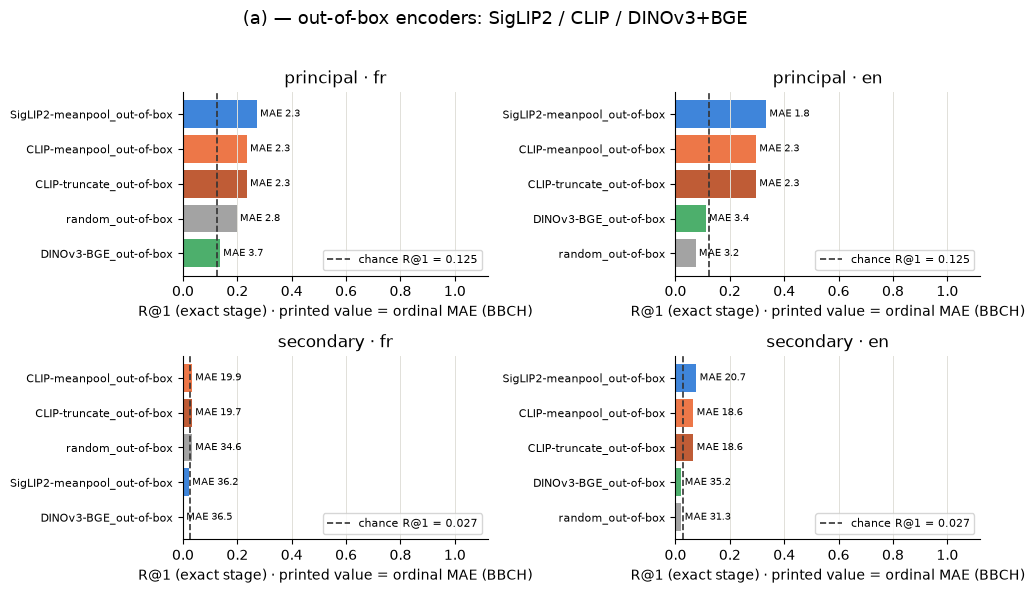

In [12]:
# --- finegrain_c0a_out_of_box.pdf : C0 (a) out-of-box encoders ------------------
# Bars = R@1 (left), the printed number = ordinal MAE. One panel per (level, lang).
OOB_KIND = {
    "00_siglip2_out_of_box": ("SigLIP2-max_out-of-box", "#1B4F91"),
    "26_zs_siglip2_trunc": ("SigLIP2-truncate_out-of-box", "#5AA0E8"),
    "26_zs_siglip2_meanpool": ("SigLIP2-meanpool_out-of-box", "#2A78D6"),
    "26_zs_clip_meanpool": ("CLIP-meanpool_out-of-box", "#EB6834"),
    "zz_clip_raw": ("CLIP-truncate_out-of-box", "#B84A20"),
    "zz_dinov3_bge_raw": ("DINOv3-BGE_out-of-box", "#3AA65C"),
    "zz_random": ("random_out-of-box", "#999999"),
}

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (level, lang) in zip(axes.ravel(), GROUPS):
    r1 = metric_by_model(level, lang, "is_correct")
    mae = metric_by_model(level, lang, "ordinal_distance")
    models = [m for m in C0_MEMBERS["a"] if m in r1.index]
    models.sort(key=lambda m: r1[m], reverse=True)   # best R@1 at the top
    y = np.arange(len(models))
    ax.barh(y, [r1[m] for m in models],
            color=[OOB_KIND[m][1] for m in models], alpha=0.9)
    for yi, m in zip(y, models):
        ax.text(r1[m] + 0.012, yi, f"MAE {mae[m]:.1f}", va="center", fontsize=7)
    chance = micro_cells(df_confusion_metrics, "chance_accuracy", level, lang)
    ax.axvline(chance, color="#333333", linestyle="--", linewidth=1.2,
               label=f"chance R@1 = {chance:.3f}")
    ax.set_yticks(y)
    ax.set_yticklabels([OOB_KIND[m][0] for m in models], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("R@1 (exact stage) · printed value = ordinal MAE (BBCH)")
    ax.set_title(f"{level} · {lang}", fontsize=12)
    ax.legend(fontsize=8, loc="lower right")
    style_ax(ax)
fig.suptitle("(a) — out-of-box encoders: SigLIP2 / CLIP / DINOv3+BGE", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_fig(fig, "finegrain_c0a_out_of_box.pdf")
plt.show()


00:49:26 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_c0b_siglip2_layers.pdf


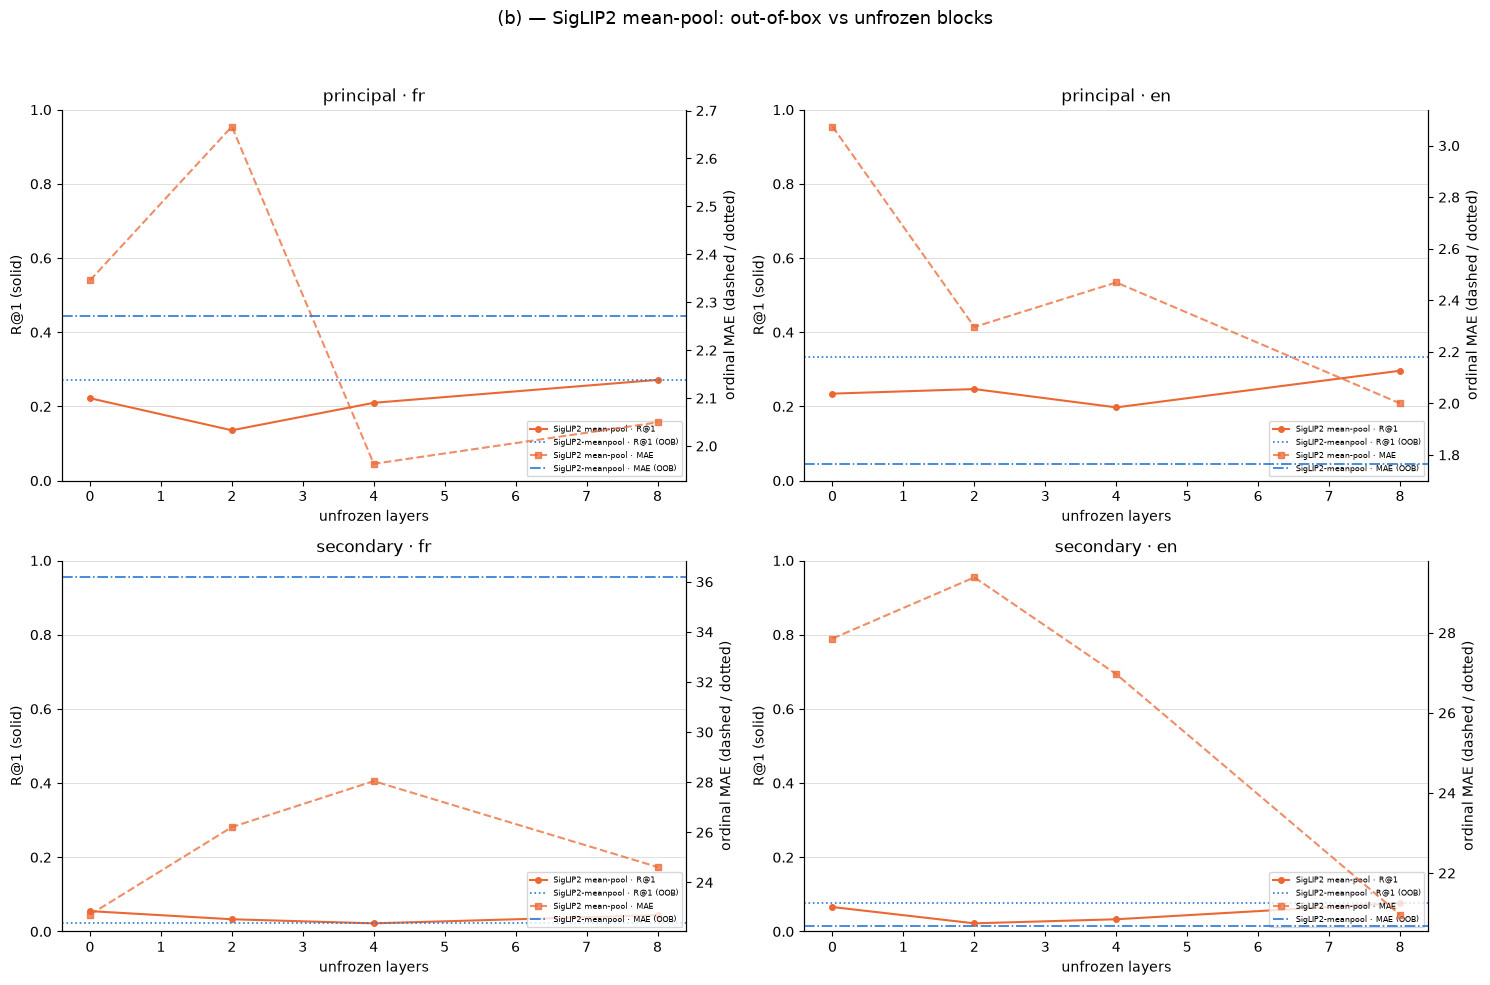

In [13]:
# --- finegrain_c0b_siglip2_layers.pdf : C0 (b) SigLIP2 mean-pool layers --------
# Solid = R@1 (left axis), dashed = ordinal MAE (right axis), dotted = OOB reference.
def sweep_panel(ax, level, lang, series, refs, logx=False):
    """Sweep lines: solid R@1 (left axis) + dashed MAE (right axis)."""
    ax2 = ax.twinx()
    for label, color, x, r1, mae in series:
        ax.plot(x, r1, "-o", color=color, markersize=4, label=f"{label} · R@1")
        ax2.plot(x, mae, "--s", color=color, markersize=4, alpha=0.75,
                 label=f"{label} · MAE")
    for label, color, r1_ref, mae_ref in refs:
        ax.axhline(r1_ref, color=color, linestyle=":", linewidth=1.2,
                   label=f"{label} · R@1 (OOB)")
        ax2.axhline(mae_ref, color=color, linestyle="-.", linewidth=1.2,
                    label=f"{label} · MAE (OOB)")
    ax.set_ylim(0, 1)
    ax.set_ylabel("R@1 (solid)")
    ax2.set_ylabel("ordinal MAE (dashed / dotted)")
    ax.set_xlabel("training-set size (log scale)" if logx else "unfrozen layers")
    if logx:
        ax.set_xscale("log")
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.7)
    ax.spines["top"].set_visible(False)
    ax2.spines["top"].set_visible(False)
    ax.set_title(f"{level} · {lang}", fontsize=12)
    # one legend for both axes: R@1 (left) + MAE (right) + OOB references
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=6, loc="lower right")


fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (level, lang) in zip(axes.ravel(), GROUPS):
    r1 = metric_by_model(level, lang, "is_correct")
    mae = metric_by_model(level, lang, "ordinal_distance")
    series = [
        ("SigLIP2 mean-pool", "#EB6834", *sweep_series("27D_last", level, lang)),
    ]
    refs = [
        ("SigLIP2-meanpool", "#2A78D6",
         r1["26_zs_siglip2_meanpool"], mae["26_zs_siglip2_meanpool"]),
    ]
    sweep_panel(ax, level, lang, series, refs)
fig.suptitle("(b) — SigLIP2 mean-pool: out-of-box vs unfrozen blocks", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "finegrain_c0b_siglip2_layers.pdf")
plt.show()


00:49:27 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_c0c_dinov3_layers.pdf


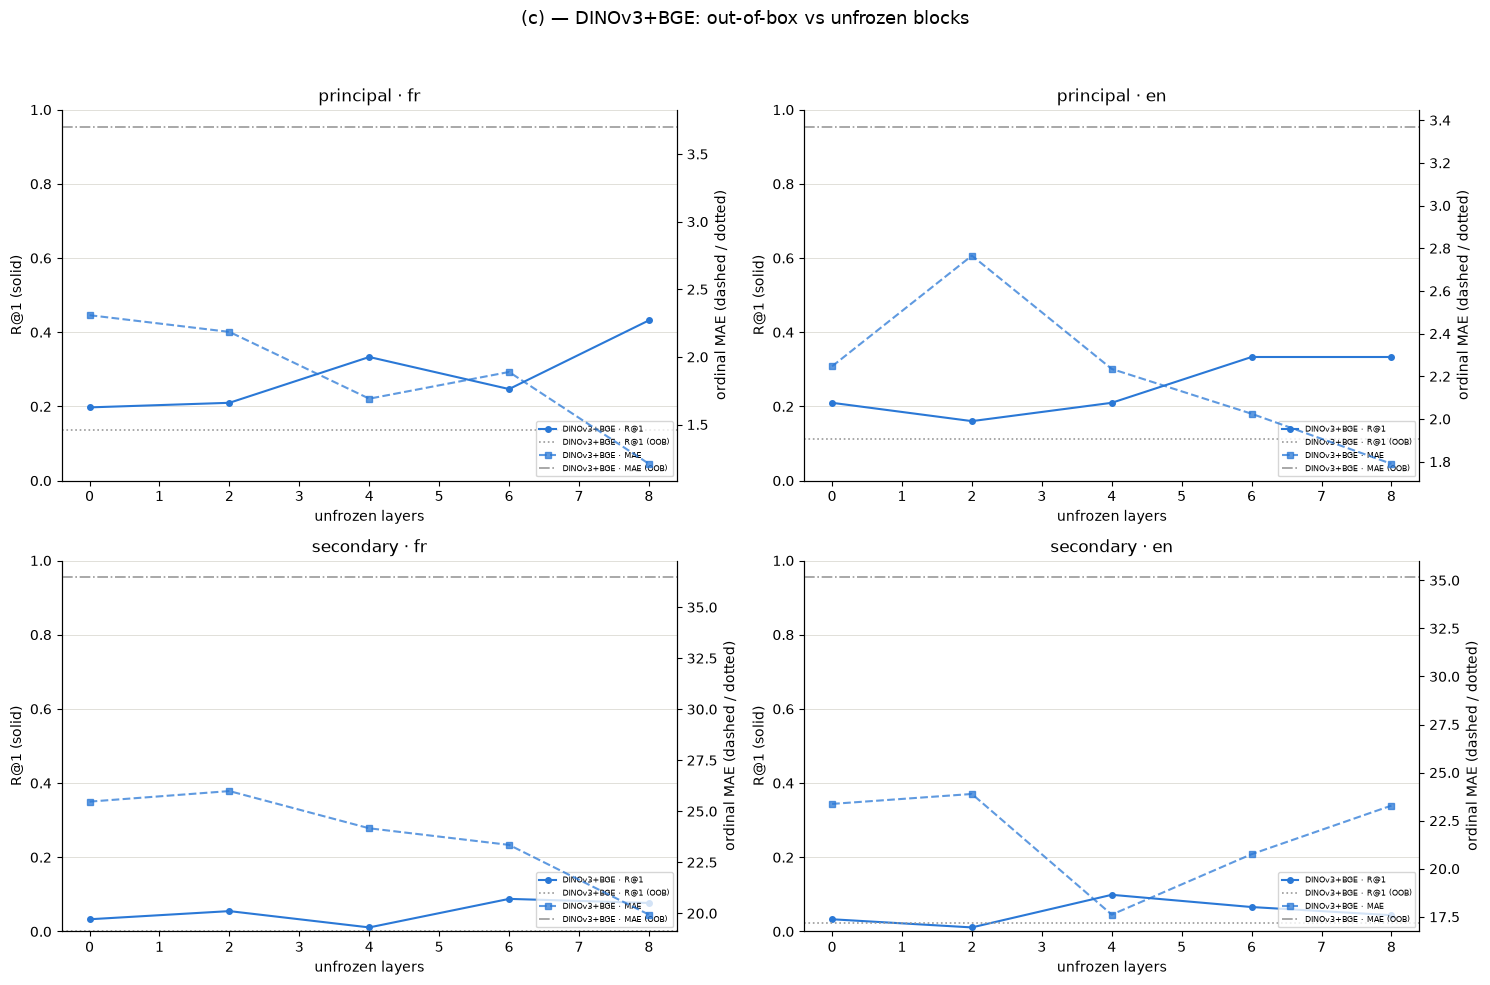

In [14]:
# --- finegrain_c0c_dinov3_layers.pdf : C0 (c) DINOv3+BGE unfrozen layers -------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (level, lang) in zip(axes.ravel(), GROUPS):
    r1 = metric_by_model(level, lang, "is_correct")
    mae = metric_by_model(level, lang, "ordinal_distance")
    series = [("DINOv3+BGE", "#2A78D6", *sweep_series("27_last", level, lang))]
    refs = [("DINOv3+BGE", "#999999", r1["zz_dinov3_bge_raw"],
             mae["zz_dinov3_bge_raw"])]
    sweep_panel(ax, level, lang, series, refs)
fig.suptitle("(c) — DINOv3+BGE: out-of-box vs unfrozen blocks", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "finegrain_c0c_dinov3_layers.pdf")
plt.show()


00:49:28 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_c0d_mining_sizes.pdf


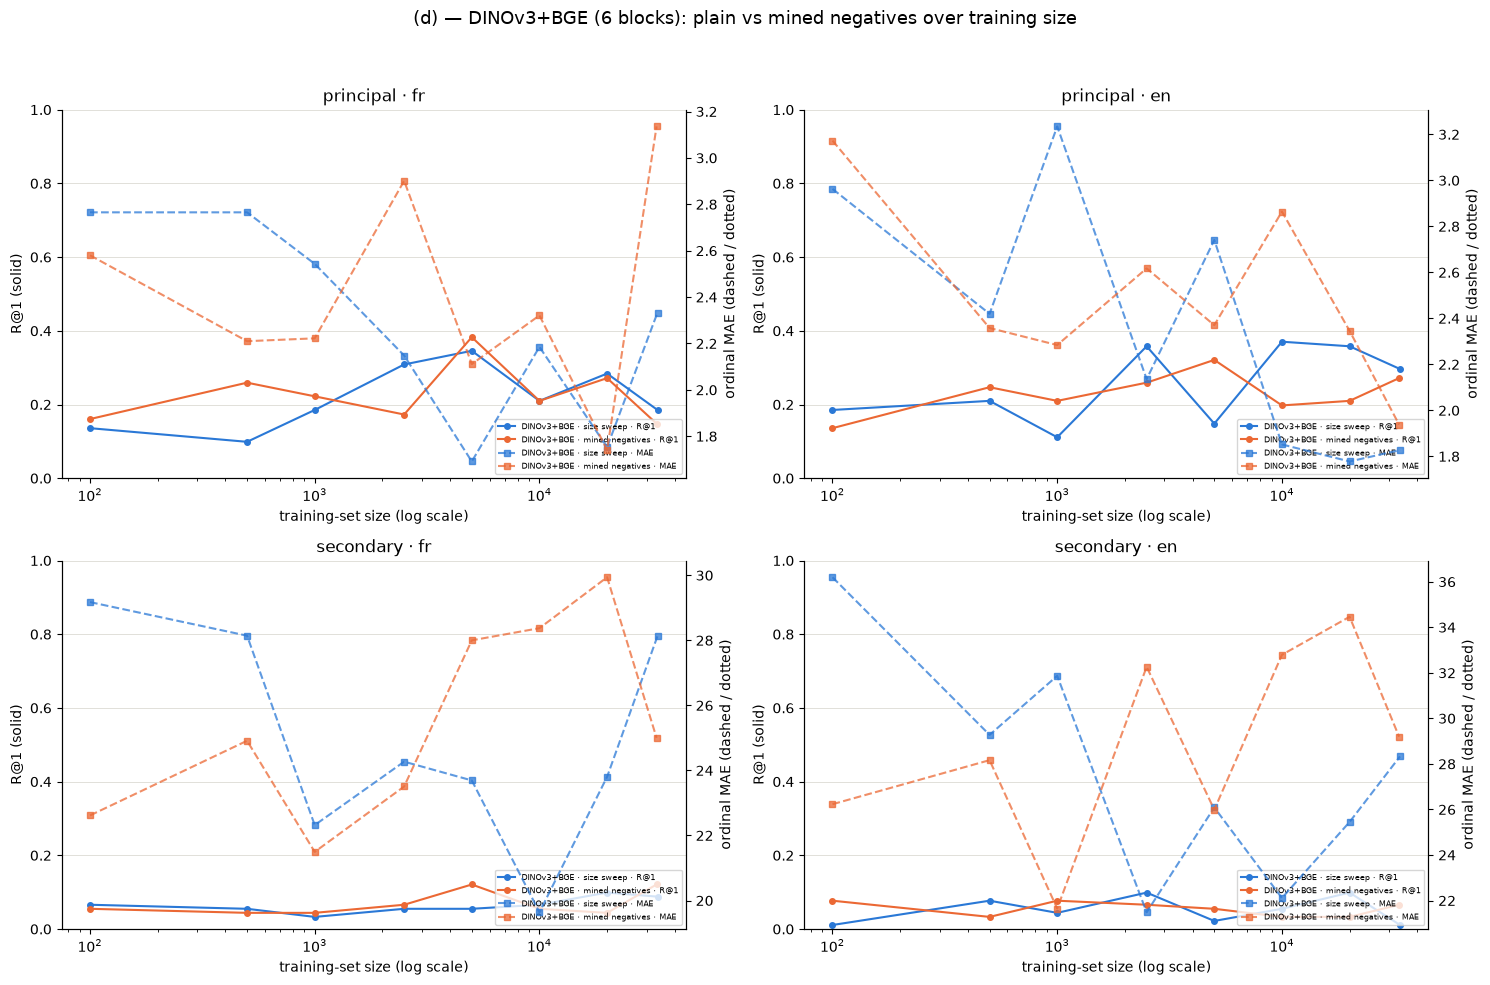

In [15]:
# --- finegrain_c0d_mining_sizes.pdf : C0 (d) training size and negative mining ---
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (level, lang) in zip(axes.ravel(), GROUPS):
    series = [
        ("DINOv3+BGE · size sweep", "#2A78D6", *sweep_series("smaller_size", level, lang)),
        ("DINOv3+BGE · mined negatives", "#EB6834", *sweep_series("29_sweep_size", level, lang)),
    ]
    sweep_panel(ax, level, lang, series, refs=[], logx=True)
fig.suptitle("(d) — DINOv3+BGE (6 blocks): plain vs mined negatives over training size",
             fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "finegrain_c0d_mining_sizes.pdf")
plt.show()


00:49:29 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_ordinal_mae.pdf


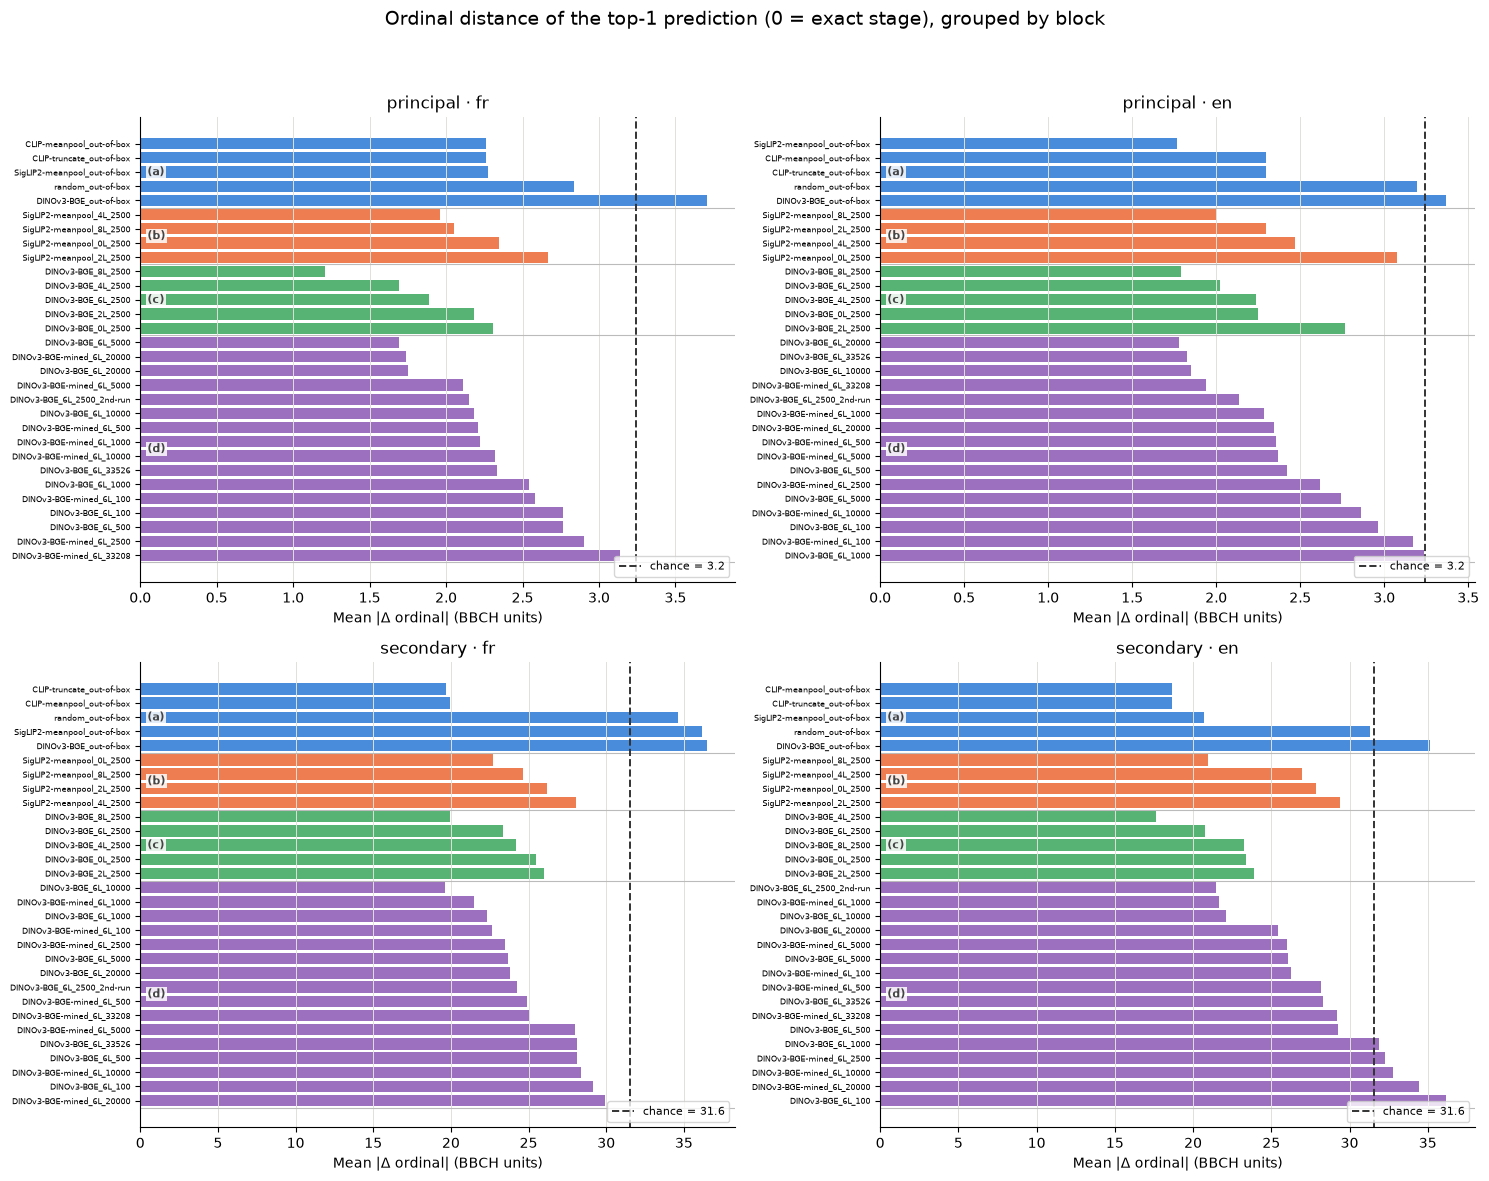

In [16]:
# --- finegrain_ordinal_mae.pdf -------------------------------------------------
# Ordinal MAE per model, laid out in C0 comparison order with (a)-(d) separators;
# one panel per (level, lang), chance line per panel.
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, (level, lang) in zip(axes.ravel(), GROUPS):
    mae = metric_by_model(level, lang, "ordinal_distance")
    ordered, bounds = c0_axis_order(mae)
    y = np.arange(len(ordered))
    ax.barh(y, [mae[m] for m in ordered],
            color=[C0_COLOR[MODEL_TO_C0[m]] for m in ordered], alpha=0.85)
    draw_c0_blocks(ax, bounds)
    chance = micro_cells(df_ordinal, "chance_mae", level, lang)
    ax.axvline(chance, color="#333333", linestyle="--", linewidth=1.4,
               label=f"chance = {chance:.1f}")
    ax.set_yticks(y)
    ax.set_yticklabels([model_label(m) for m in ordered], fontsize=6)
    ax.invert_yaxis()
    ax.set_xlabel("Mean |Δ ordinal| (BBCH units)")
    ax.set_title(f"{level} · {lang}", fontsize=12)
    ax.legend(fontsize=8, loc="lower right")
    style_ax(ax)
fig.suptitle("Ordinal distance of the top-1 prediction (0 = exact stage), "
             "grouped by block", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "finegrain_ordinal_mae.pdf")
plt.show()


00:49:30 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_ordinal_mae_families.pdf


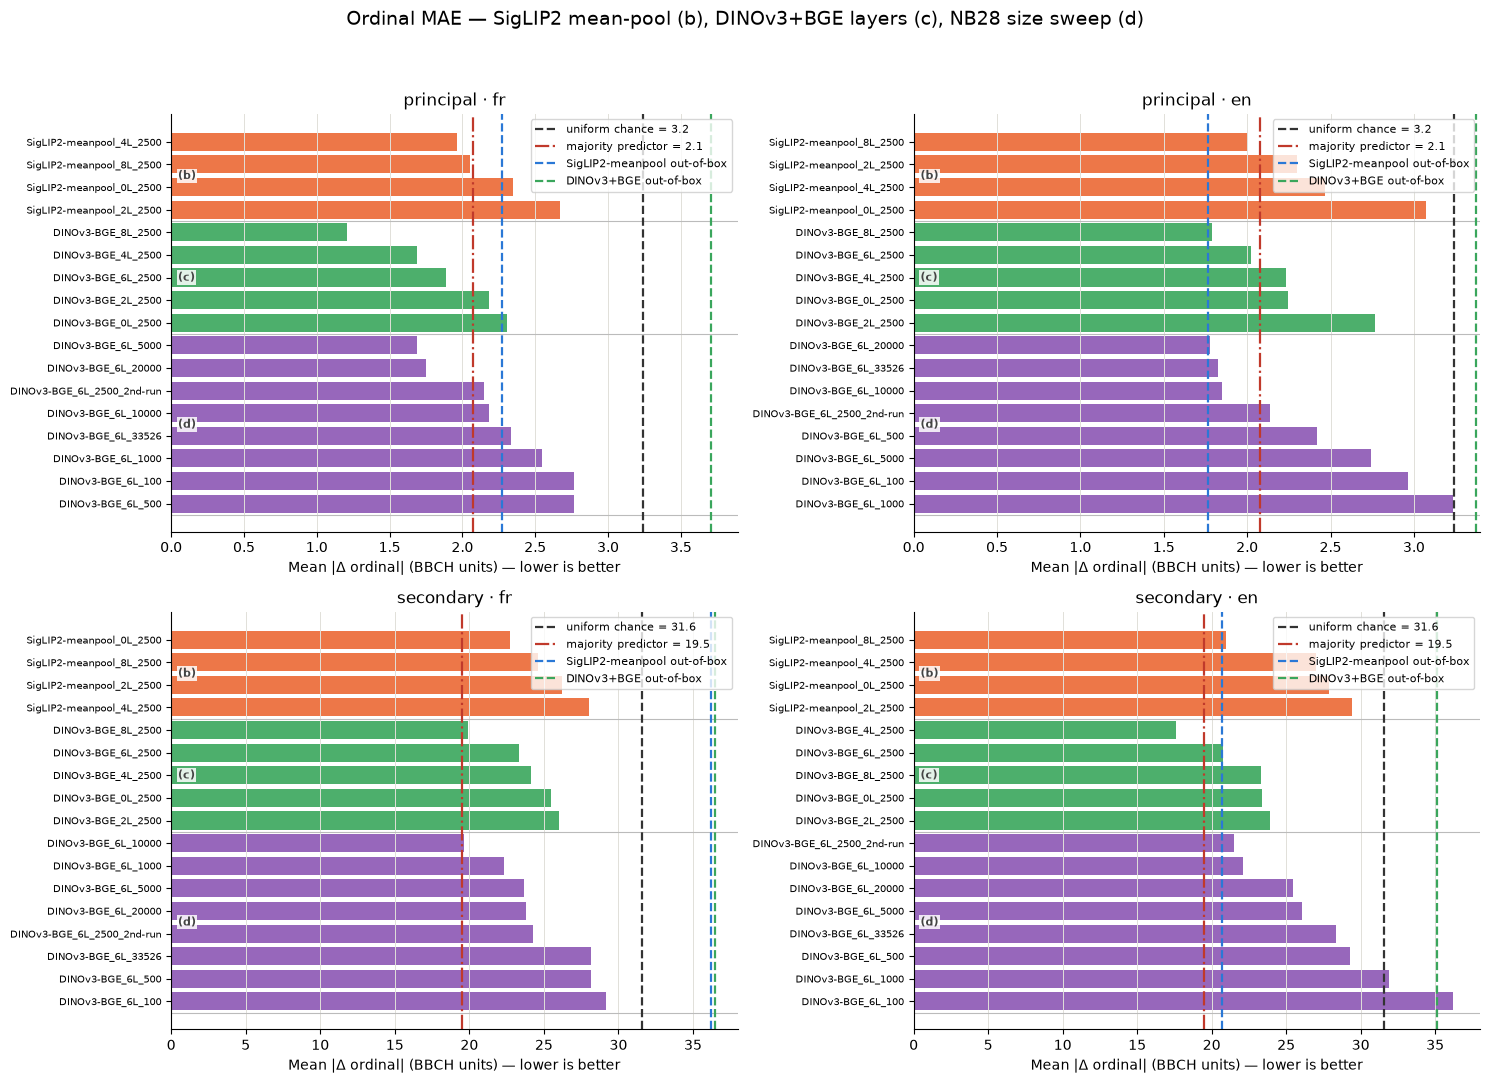

In [17]:
# --- finegrain_ordinal_mae_families.pdf ---------------------------------------
# Ordinal MAE for the fine-tuned families only: (b) SigLIP2 mean-pool, (c) DINOv3+BGE
# layers, and the NB28 plain size sweep. The two out-of-box encoders are drawn as
# vertical references (they are not part of the bars), together with exact chance.
SELECTED = ([("b", m) for m in C0_MEMBERS["b"]]
            + [("c", m) for m in C0_MEMBERS["c"]]
            + [("d", m) for m in C0_MEMBERS["d"] if m.startswith("smaller_size_")])
COLOR_OF = {m: key for key, m in SELECTED}


def majority_mae(level, lang):
    """MAE of always predicting each crop's modal ground-truth stage.

    One modal stage is chosen per evaluated crop (a single pooled modal stage would not
    be in every crop's candidate pool); the absolute ordinal errors of those constant
    predictions are then pooled photo-by-photo over the crops.
    """
    errors = []
    for (crop, lvl) in EVALUATED_PAIRS:
        if lvl != level:
            continue
        photos = (df_pred[(df_pred["crop_name"] == crop)
                          & (df_pred["level"] == lvl)
                          & (df_pred["lang"] == lang)
                          & (df_pred["model_id"] == MODEL_IDS[0])]
                  .drop_duplicates("photo_name"))
        if photos.empty:
            continue
        majority_id = photos["gt_id"].value_counts().idxmax()
        majority_ord = float(photos.loc[photos["gt_id"] == majority_id,
                                        "gt_ordinal"].iloc[0])
        errors.append(np.abs(photos["gt_ordinal"].to_numpy(dtype=float) - majority_ord))
    return float(np.concatenate(errors).mean())

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, (level, lang) in zip(axes.ravel(), GROUPS):
    mae = metric_by_model(level, lang, "ordinal_distance")
    ordered, bounds = [], {}
    for key in ("b", "c", "d"):
        members = [m for k, m in SELECTED if k == key and m in mae.index]
        members.sort(key=lambda m: mae[m])
        bounds[key] = (len(ordered), len(ordered) + len(members))
        ordered += members
    y = np.arange(len(ordered))
    ax.barh(y, [mae[m] for m in ordered],
            color=[C0_COLOR[COLOR_OF[m]] for m in ordered], alpha=0.9)
    draw_c0_blocks(ax, bounds)
    chance = micro_cells(df_ordinal, "chance_mae", level, lang)
    ax.axvline(chance, color="#333333", linestyle="--", linewidth=1.6,
               label=f"uniform chance = {chance:.1f}")
    majority = majority_mae(level, lang)
    ax.axvline(majority, color="#C0392B", linestyle="-.", linewidth=1.6,
               label=f"majority predictor = {majority:.1f}")
    ax.axvline(mae["26_zs_siglip2_meanpool"], color="#2A78D6", linestyle="--",
               linewidth=1.6, label="SigLIP2-meanpool out-of-box")
    ax.axvline(mae["zz_dinov3_bge_raw"], color="#3AA65C", linestyle="--",
               linewidth=1.6, label="DINOv3+BGE out-of-box")
    ax.set_yticks(y)
    ax.set_yticklabels([model_label(m) for m in ordered], fontsize=7)
    ax.invert_yaxis()
    ax.set_xlabel("Mean |Δ ordinal| (BBCH units) — lower is better")
    ax.set_title(f"{level} · {lang}", fontsize=12)
    ax.legend(fontsize=8, loc="upper right")
    style_ax(ax)
fig.suptitle("Ordinal MAE — SigLIP2 mean-pool (b), DINOv3+BGE layers (c), "
             "NB28 size sweep (d)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "finegrain_ordinal_mae_families.pdf")
plt.show()


00:49:30 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_ordinal_distance_cdf.pdf


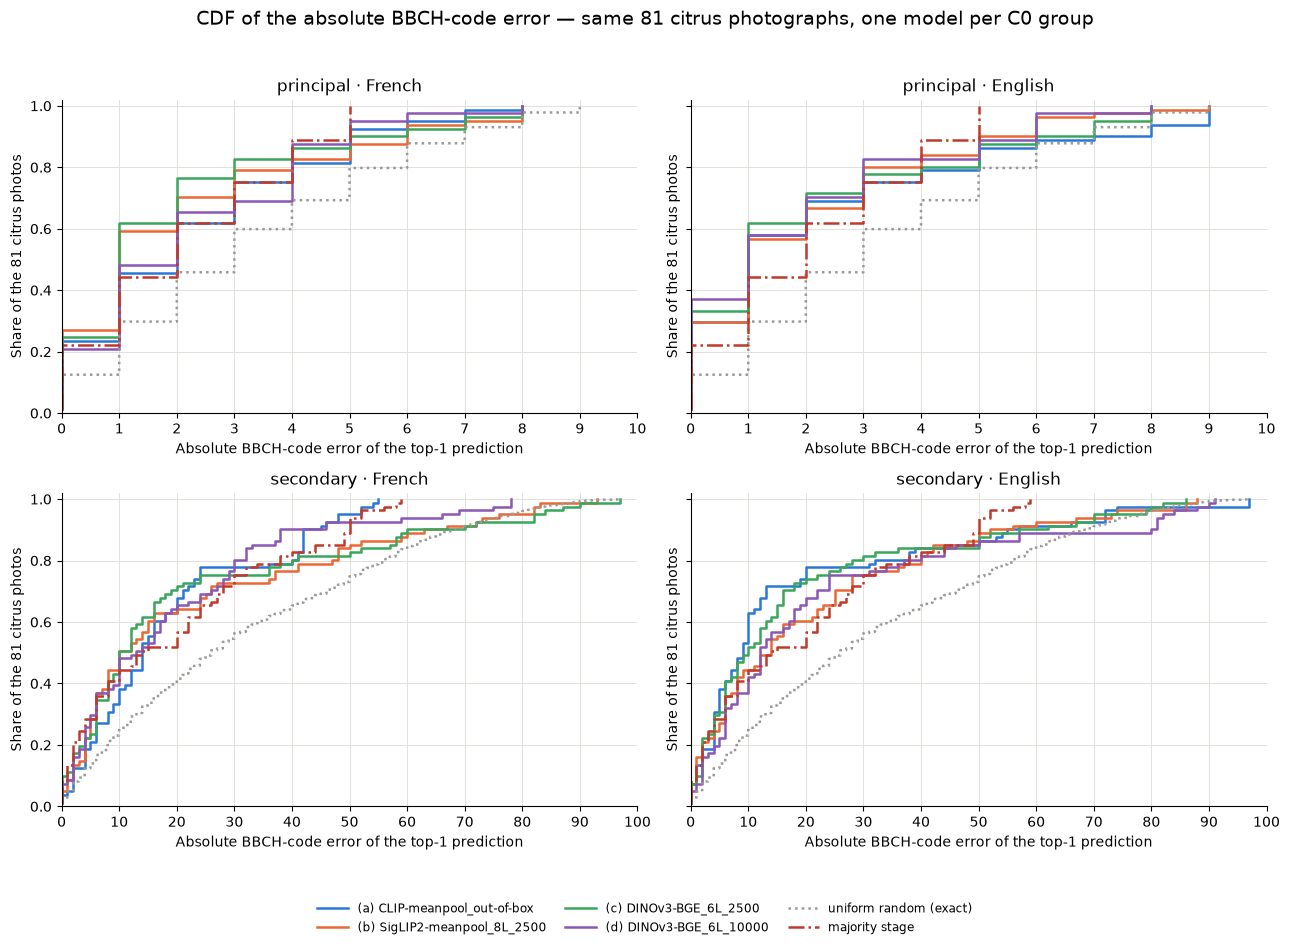

In [18]:
# --- finegrain_ordinal_distance_cdf.pdf ----------------------------------------
# CDF of the top-1 absolute BBCH-code error for the SAME 81 citrus photographs in
# every panel. Rows = level (principal / secondary), columns = language (fr / en).
# One model per C0 group is used in ALL panels — chosen by its mean within-level MAE
# rank across both levels and languages — so French and English (and principal and
# secondary) are matched model-for-model and each colour denotes a single checkpoint.
# Two baselines are included:
#   * uniform random — every candidate stage of the pool is equally likely (exact null);
#   * majority stage — always predict the modal ground-truth stage of the level, and
#     show its per-photo error distribution.
CDF_CROP = "citrus"


def citrus_photo_rows(level, lang):
    """The 81 citrus photos with their ground-truth ordinal (one row per photo)."""
    photos = df_pred[(df_pred["crop_name"] == CDF_CROP)
                     & (df_pred["level"] == level)
                     & (df_pred["lang"] == lang)
                     & (df_pred["model_id"] == MODEL_IDS[0])]
    return photos.drop_duplicates("photo_name")


def uniform_distances(level, lang):
    """Exact uniform-random null: every pool candidate for every citrus photo."""
    pool = np.array([float(ordinals[(CDF_CROP, level)][s]["ordinal"])
                     for s in pool_ids[(CDF_CROP, level)]])
    gt = citrus_photo_rows(level, lang)["gt_ordinal"].to_numpy(dtype=float)
    return np.abs(pool[:, None] - gt[None, :]).ravel()


def majority_distances(level, lang):
    """Per-photo errors of the majority-stage predictor for this level."""
    photos = citrus_photo_rows(level, lang)
    majority_id = photos["gt_id"].value_counts().idxmax()
    majority_ord = float(ordinals[(CDF_CROP, level)][majority_id]["ordinal"])
    return np.abs(photos["gt_ordinal"].to_numpy(dtype=float) - majority_ord)


def ecdf(values):
    x = np.sort(np.asarray(values, dtype=float))
    return x, np.arange(1, len(x) + 1) / len(x)


for level in ("principal", "secondary"):
    for lang in LANGUAGES:
        assert len(citrus_photo_rows(level, lang)) == 81, \
            f"{level}/{lang}: expected the 81 citrus photos"


# Rank models inside each level first, so the (much larger) secondary MAE does not
# dominate the choice; the model with the best mean rank in its C0 group is kept.
level_rank = []
for level in ("principal", "secondary"):
    mae = (df_pred[(df_pred["crop_name"] == CDF_CROP) & (df_pred["level"] == level)]
           .groupby("model_id")["ordinal_distance"].mean())
    level_rank.append(mae.rank(method="average"))
chosen = best_per_c0(sum(level_rank) / len(level_rank))

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), sharex="row", sharey=True)
for i, level in enumerate(("principal", "secondary")):
    for j, lang in enumerate(LANGUAGES):
        ax = axes[i, j]
        for key in C0_ORDER:
            if key not in chosen:
                continue
            model_id = chosen[key]
            d = df_pred[(df_pred["model_id"] == model_id)
                        & (df_pred["crop_name"] == CDF_CROP)
                        & (df_pred["level"] == level)
                        & (df_pred["lang"] == lang)]["ordinal_distance"].to_numpy()
            x, y = ecdf(d)
            ax.plot(x, y, drawstyle="steps-post", color=C0_COLOR[key], linewidth=1.8,
                    label=f"({key}) {model_label(model_id)}")

        xu, yu = ecdf(uniform_distances(level, lang))
        ax.plot(xu, yu, drawstyle="steps-post", color="#999999", linestyle=":",
                linewidth=1.8, label="uniform random (exact)")
        xm, ym = ecdf(majority_distances(level, lang))
        ax.plot(xm, ym, drawstyle="steps-post", color="#C0392B", linestyle="-.",
                linewidth=1.8, label="majority stage")

        if level == "principal":
            ax.set_xlim(0, 10)
            ax.set_xticks(range(0, 11))
        else:
            ax.set_xlim(0, 100)
            ax.set_xticks(range(0, 101, 10))
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("Absolute BBCH-code error of the top-1 prediction", fontsize=10)
        ax.set_ylabel("Share of the 81 citrus photos", fontsize=10)
        ax.set_title(f"{level} · {'French' if lang == 'fr' else 'English'}", fontsize=12)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(color=GRID_COLOR, linewidth=0.7)

# one compact legend shared by all four panels (deduplicated across rows)
handles, labels, seen = [], [], set()
for ax in axes.ravel():
    for handle, label in zip(*ax.get_legend_handles_labels()):
        if label not in seen:
            seen.add(label)
            handles.append(handle)
            labels.append(label)
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8.5,
           frameon=False, handlelength=2.6, columnspacing=1.6)
fig.suptitle("CDF of the absolute BBCH-code error — same 81 citrus photographs, "
             "one model per C0 group", fontsize=14)
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
save_fig(fig, "finegrain_ordinal_distance_cdf.pdf")
plt.show()


00:49:32 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_ordinal_delta_distribution.pdf


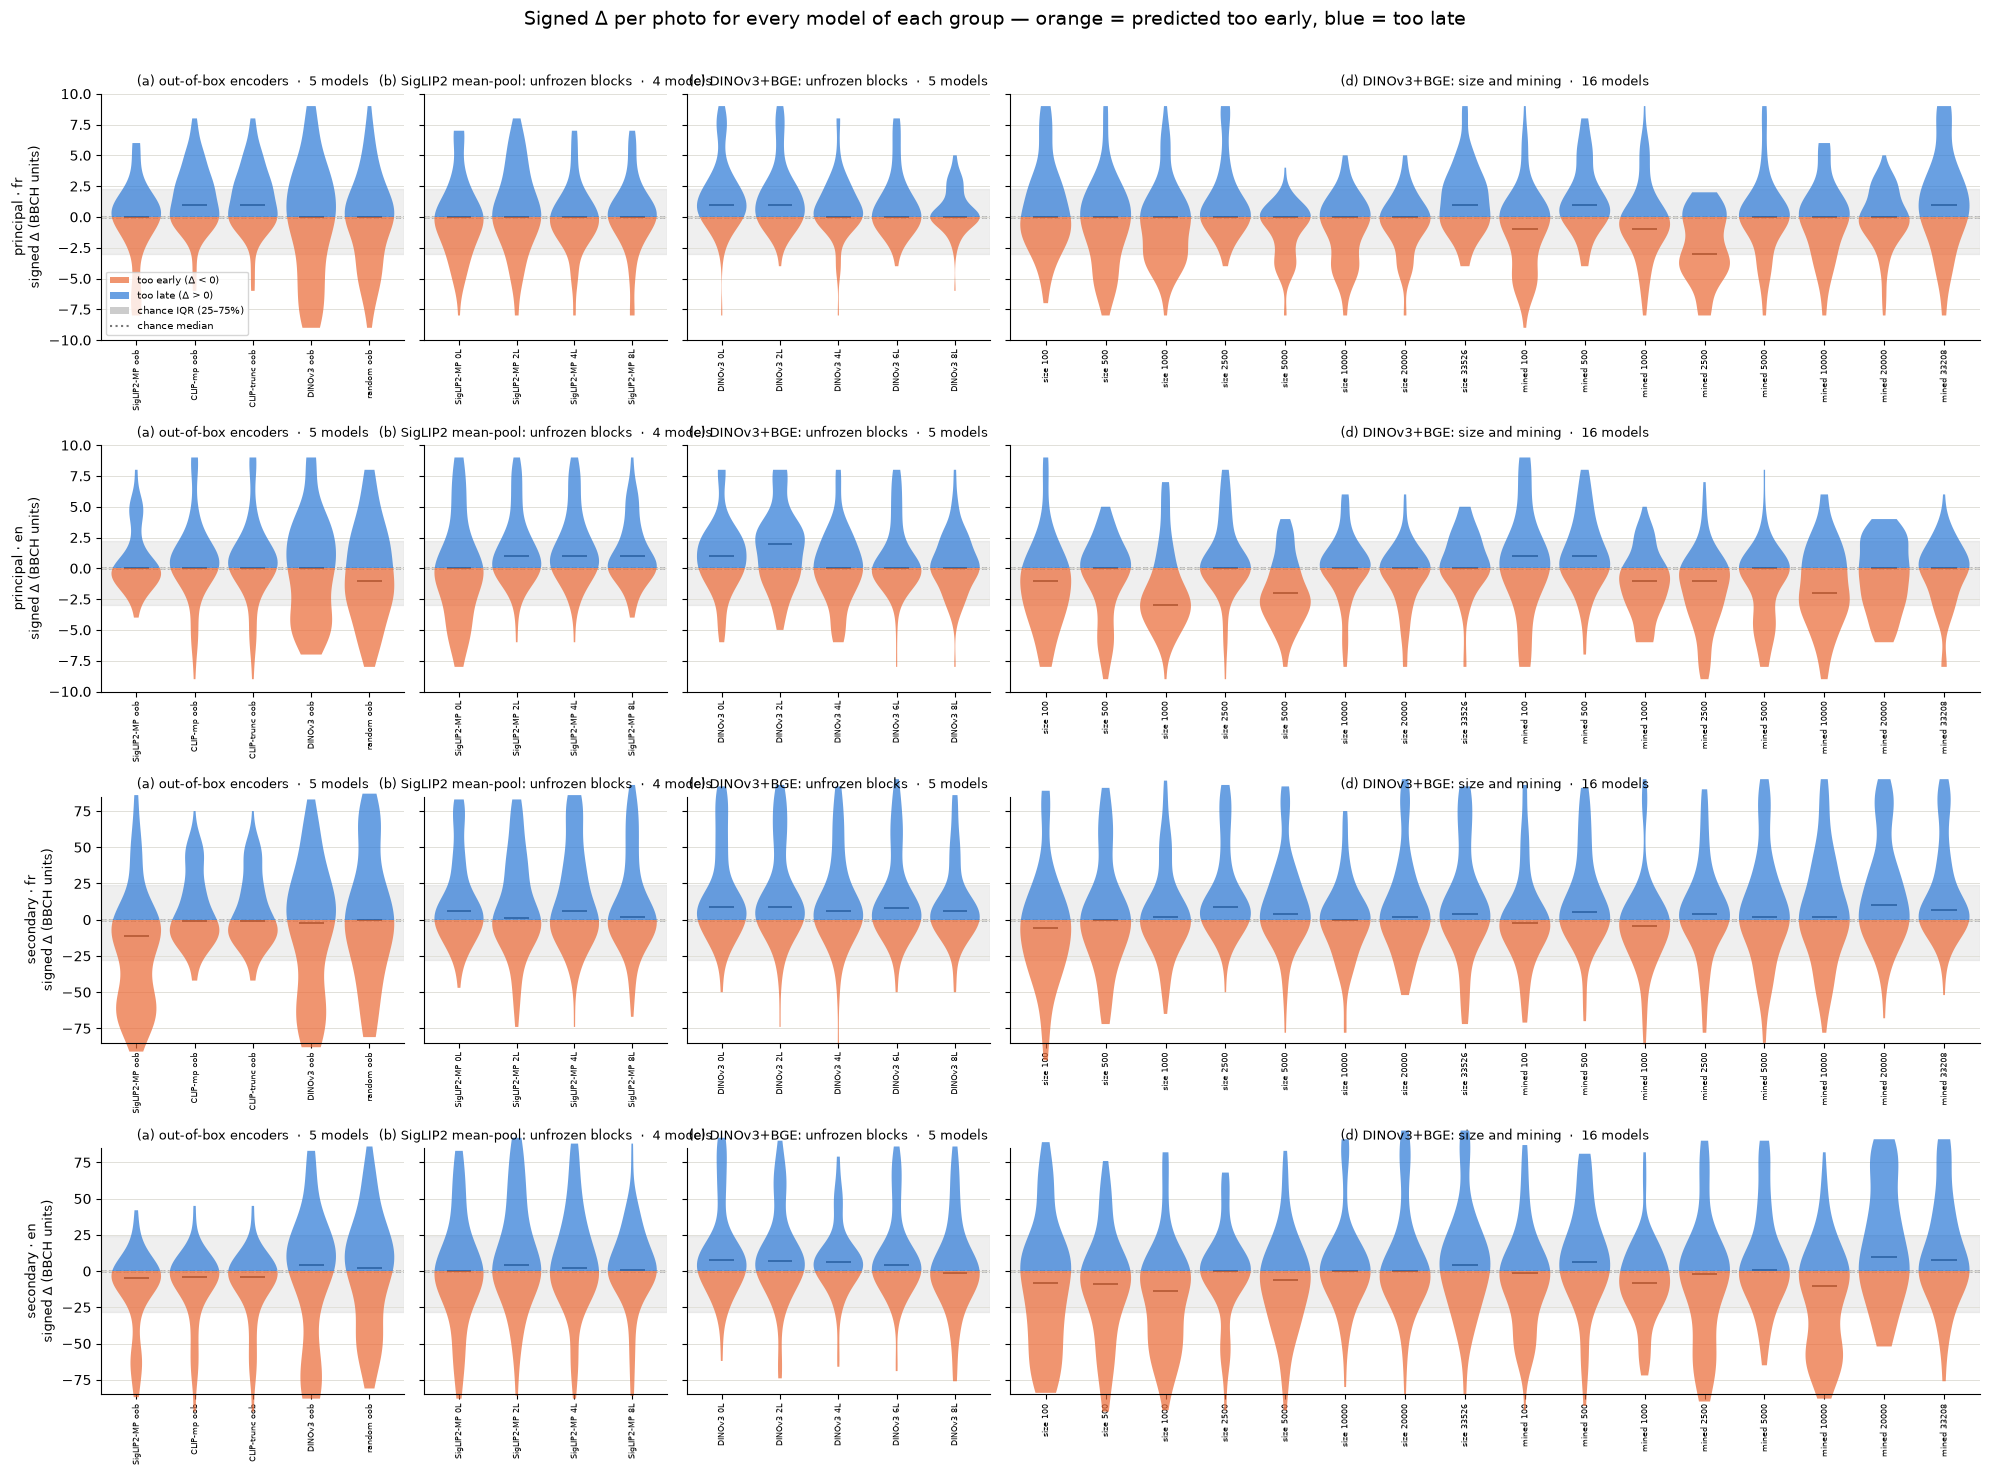

In [19]:
# --- finegrain_ordinal_delta_distribution.pdf ----------------------------------
# Signed per-photo delta (pred - truth, BBCH units) for EVERY model of each C0 group,
# one subplot per group and one row per (level, language):
#   below 0 = predicted too early (orange) · above 0 = too late (blue)
# The grey band is the exact chance inter-quartile range (25-75%) and the dotted line
# its median, so each model's shift and spread can be read against the null.
from matplotlib.patches import Patch, PathPatch, Rectangle
from matplotlib.lines import Line2D


def chance_signed_deltas(level, lang):
    """Exact null: every pool candidate minus the truth, over the scored photos."""
    parts = []
    for (crop, lvl) in EVALUATED_PAIRS:
        if lvl != level:
            continue
        pool = np.array([float(ordinals[(crop, lvl)][s]["ordinal"])
                         for s in pool_ids[(crop, lvl)]])
        photos = df_pred[(df_pred["crop_name"] == crop) & (df_pred["level"] == lvl)
                         & (df_pred["lang"] == lang)
                         & (df_pred["model_id"] == MODEL_IDS[0])]
        gt = photos["gt_ordinal"].to_numpy(dtype=float)
        parts.append((pool[:, None] - gt[None, :]).ravel())
    return np.concatenate(parts)


def violin_split(ax, values, position, width, early_color, late_color):
    """Vertical violin whose two halves are coloured by the sign of the delta."""
    values = np.asarray(values, dtype=float)
    if np.ptp(values) == 0:             # degenerate: a KDE would be singular
        ax.vlines(position, values[0] - 0.35, values[0] + 0.35,
                  color=early_color if values[0] < 0 else late_color, linewidth=4)
        return None
    parts = ax.violinplot([values], positions=[position], widths=width,
                          showmedians=True, showextrema=False)
    body = parts["bodies"][0]
    body.set_visible(False)
    path = body.get_paths()[0]          # PolyCollection (not a Patch)
    for y0, color in ((-1e6, early_color), (0.0, late_color)):
        patch = PathPatch(path, facecolor=color, edgecolor="none", alpha=0.7,
                          transform=ax.transData, zorder=2)
        ax.add_patch(patch)
        patch.set_clip_path(Rectangle((-1e6, y0), 2e6, 1e6, transform=ax.transData))
    parts["cmedians"].set_color("#333333")
    parts["cmedians"].set_linewidth(1.2)
    return parts


def nice_limit(values):
    """Y half-range for one row (95th percentile, so one extreme guess cannot stretch it)."""
    q = float(np.percentile(np.abs(values), 95))
    return float(min(max(np.ceil(q / 5) * 5, 5), 100))


def short_model_label(model_id):
    """Compact tick label for the per-group delta figure."""
    if model_id == "00_siglip2_out_of_box":
        return "SigLIP2-max oob"
    if model_id == "26_zs_siglip2_trunc":
        return "SigLIP2-trunc oob"
    if model_id == "26_zs_siglip2_meanpool":
        return "SigLIP2-MP oob"
    if model_id == "26_zs_clip_meanpool":
        return "CLIP-mp oob"
    if model_id == "zz_clip_raw":
        return "CLIP-trunc oob"
    if model_id == "zz_dinov3_bge_raw":
        return "DINOv3 oob"
    if model_id == "zz_random":
        return "random oob"
    if model_id.startswith("27D_last_"):
        return f"SigLIP2-MP {model_id.rsplit('_', 1)[1]}L"
    if model_id.startswith("27_last_"):
        return f"DINOv3 {model_id.rsplit('_', 1)[1]}L"
    if model_id.startswith("smaller_size_"):
        return f"size {model_id.rsplit('_', 1)[1]}"
    if model_id.startswith("29_sweep_size_"):
        return f"mined {model_id.rsplit('_', 1)[1]}"
    return model_id


ROWS = [(level, lang) for level in ("principal", "secondary") for lang in LANGUAGES]
EARLY, LATE = "#EB6834", "#2A78D6"

model_deltas = {}
for (level, lang) in ROWS:
    for model_id in MODEL_IDS:
        model_deltas[(level, lang, model_id)] = df_pred[
            (df_pred["model_id"] == model_id) & (df_pred["level"] == level)
            & (df_pred["lang"] == lang)]["signed_distance"].to_numpy(dtype=float)

# one constant slot per model: subplot widths are proportional to the group size, so
# group (d) (16 models) is three times wider than group (c) (5 models)
GROUP_WIDTH = {k: len([m for m in C0_MEMBERS[k] if m in MODEL_IDS]) for k in C0_ORDER}
MODEL_SLOT_IN = 0.62
fig_w = 1.4 + MODEL_SLOT_IN * sum(GROUP_WIDTH.values())

fig, axes = plt.subplots(len(ROWS), len(C0_ORDER),
                         figsize=(fig_w, 15), sharey="row", squeeze=False,
                         gridspec_kw={"width_ratios": [GROUP_WIDTH[k] for k in C0_ORDER]})
for i, (level, lang) in enumerate(ROWS):
    chance = chance_signed_deltas(level, lang)
    q25, med, q75 = np.percentile(chance, [25, 50, 75])
    row_vals = np.concatenate([model_deltas[(level, lang, m)]
                               for m in MODEL_IDS if (level, lang, m) in model_deltas])
    lim = nice_limit(row_vals)

    for j, key in enumerate(C0_ORDER):
        ax = axes[i, j]
        members = [m for m in C0_MEMBERS[key] if (level, lang, m) in model_deltas]
        ax.axhspan(q25, q75, color="#999999", alpha=0.15, zorder=0)
        ax.axhline(med, color="#777777", linestyle=":", linewidth=1.0, zorder=1)
        ax.axhline(0, color="#333333", linestyle="--", linewidth=1.0, zorder=1)
        for x, model_id in enumerate(members):
            violin_split(ax, model_deltas[(level, lang, model_id)], x, 0.85,
                         EARLY, LATE)
        ax.set_xticks(range(len(members)))
        ax.set_xticklabels([short_model_label(m) for m in members],
                           rotation=90, fontsize=6)
        ax.set_xlim(-0.6, len(members) - 0.4)
        ax.set_ylim(-lim, lim)
        ax.set_title(f"({key}) {C0_SHORT[key]}  ·  {len(members)} models", fontsize=9)
        if j == 0:
            ax.set_ylabel(f"{level} · {lang}\nsigned Δ (BBCH units)", fontsize=9)
        ax.grid(axis="y", color=GRID_COLOR, linewidth=0.7)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

axes[0, 0].legend(
    handles=[Patch(facecolor=EARLY, alpha=0.7, label="too early (Δ < 0)"),
             Patch(facecolor=LATE, alpha=0.7, label="too late (Δ > 0)"),
             Patch(facecolor="#CCCCCC", label="chance IQR (25–75%)"),
             Line2D([0], [0], color="#777777", linestyle=":", label="chance median")],
    fontsize=7, loc="lower left")
fig.suptitle("Signed Δ per photo for every model of each group — "
             "orange = predicted too early, blue = too late", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
save_fig(fig, "finegrain_ordinal_delta_distribution.pdf")
plt.show()



00:49:33 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_principal_consistency.pdf


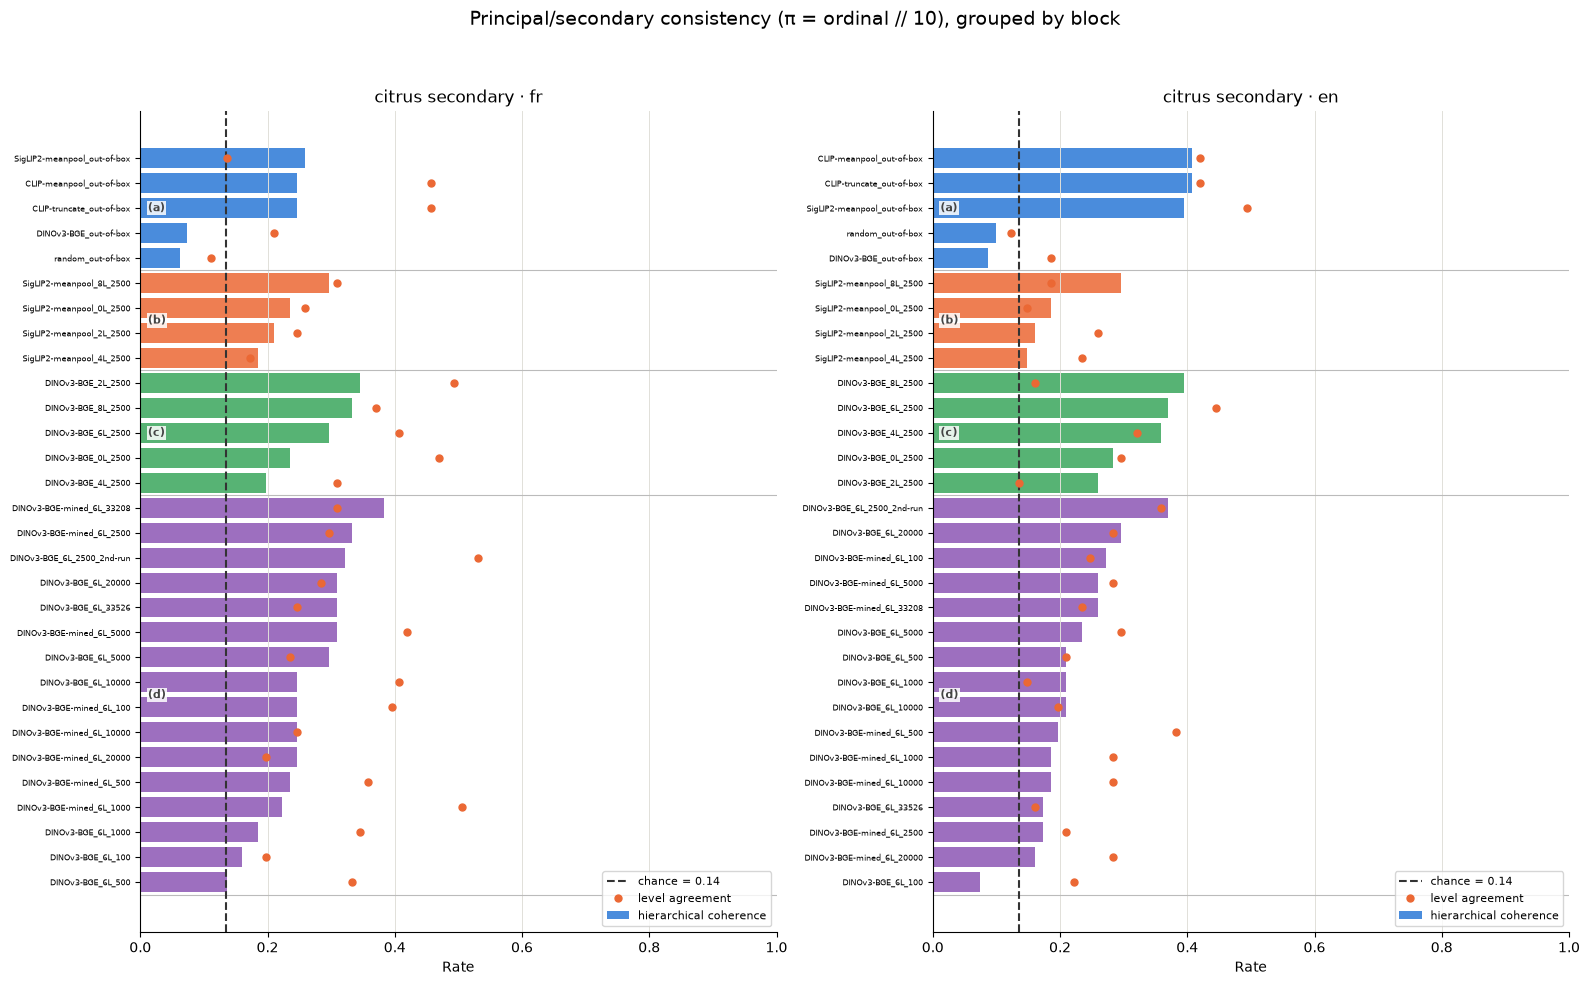

In [20]:
# --- finegrain_principal_consistency.pdf ---------------------------------------
# Hierarchical coherence (citrus secondary) per model in C0 order, vs chance, with the
# level-agreement rate as a marker.
fig, axes = plt.subplots(1, 2, figsize=(16, 10))
for ax, lang in zip(axes, LANGUAGES):
    sub = df_pred[(df_pred["crop_name"] == "citrus") & (df_pred["level"] == "secondary")
                  & (df_pred["lang"] == lang)]
    coh = sub.groupby("model_id")["principal_match"].mean()
    ordered, bounds = c0_axis_order(coh, ascending=False)
    y = np.arange(len(ordered))
    ax.barh(y, [coh[m] for m in ordered],
            color=[C0_COLOR[MODEL_TO_C0[m]] for m in ordered], alpha=0.85,
            label="hierarchical coherence")
    draw_c0_blocks(ax, bounds)
    chance = float(df_pc[(df_pc["crop_name"] == "citrus") & (df_pc["lang"] == lang)]
                   ["chance_coherence"].mean())
    ax.axvline(chance, color="#333333", linestyle="--", linewidth=1.5,
               label=f"chance = {chance:.2f}")
    agreement = (df_pc[(df_pc["crop_name"] == "citrus") & (df_pc["lang"] == lang)]
                 .set_index("model_id")["level_agreement"].reindex(ordered))
    ax.plot(agreement.values, y, "o", color="#EB6834", markersize=5,
            label="level agreement")
    ax.set_yticks(y)
    ax.set_yticklabels([model_label(m) for m in ordered], fontsize=6)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.0)
    ax.set_xlabel("Rate", fontsize=10)
    ax.set_title(f"citrus secondary · {lang}", fontsize=12)
    ax.legend(fontsize=8, loc="lower right")
    style_ax(ax)
fig.suptitle("Principal/secondary consistency (π = ordinal // 10), grouped by block",
             fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "finegrain_principal_consistency.pdf")
plt.show()


00:49:34 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_pred_vs_gt_ordinal.pdf


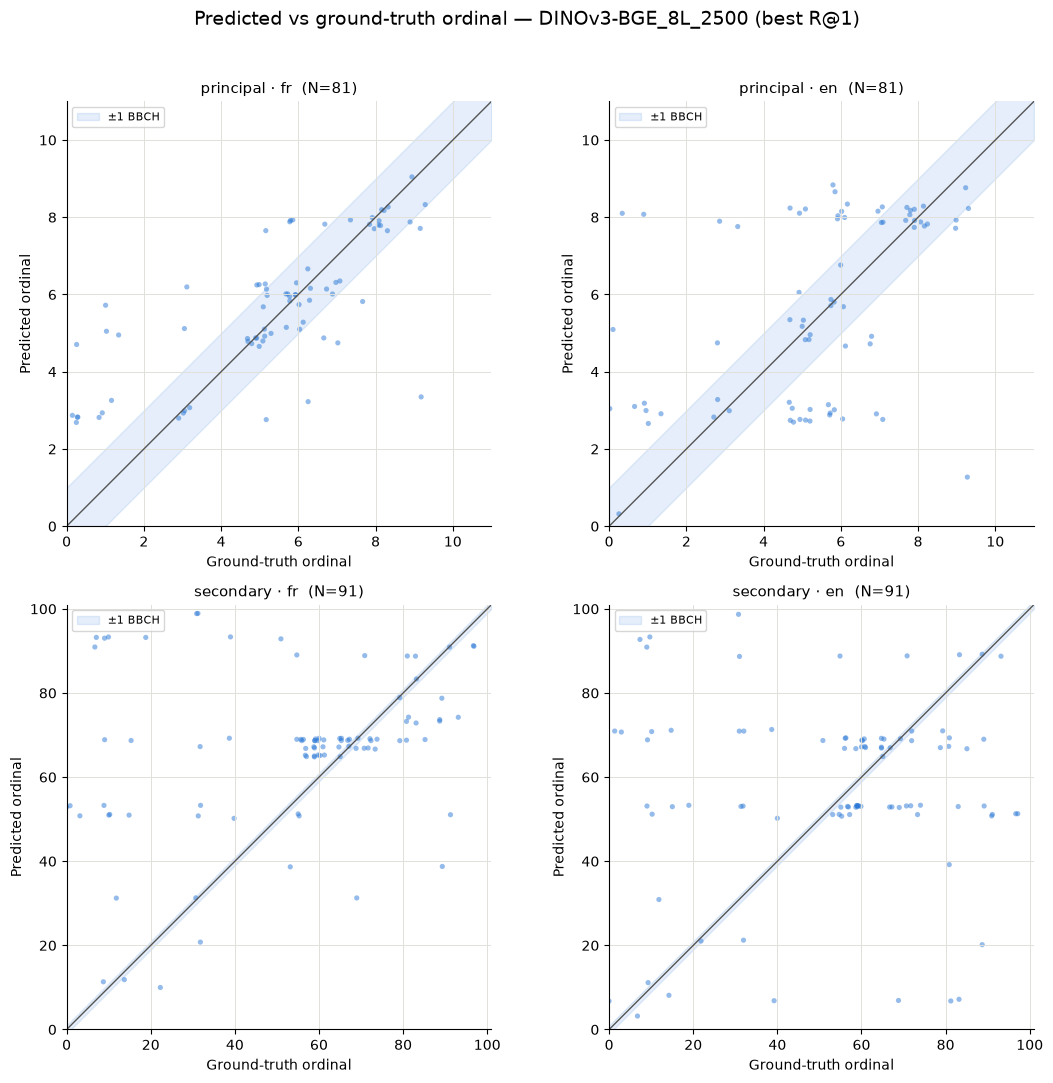

In [21]:
# --- finegrain_pred_vs_gt_ordinal.pdf ------------------------------------------
# Predicted vs ground-truth ordinal scatter (jittered) for the best model by
# micro R@1, one panel per (level, lang), diagonal + ±1 band.
best_model = (df_pred.groupby("model_id")["is_correct"].mean()
              .sort_values(ascending=False).index[0])
rng = np.random.default_rng(20261020)

fig, axes = plt.subplots(2, 2, figsize=(11, 11))
for ax, (level, lang) in zip(axes.ravel(), GROUPS):
    sub = df_pred[(df_pred["model_id"] == best_model)
                  & (df_pred["level"] == level) & (df_pred["lang"] == lang)]
    gt = sub["gt_ordinal"].to_numpy(dtype=float)
    pr = sub["pred_ordinal"].to_numpy(dtype=float)
    lim = max(gt.max(), pr.max()) + 2
    ax.fill_between([0, lim], [-1, lim - 1], [1, lim + 1],
                    color="#2A78D6", alpha=0.12, label="±1 BBCH")
    ax.plot([0, lim], [0, lim], color="#555555", linewidth=1)
    ax.scatter(gt + rng.uniform(-0.35, 0.35, len(gt)),
               pr + rng.uniform(-0.35, 0.35, len(pr)),
               s=14, alpha=0.5, color="#2A78D6", edgecolors="none")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("Ground-truth ordinal", fontsize=10)
    ax.set_ylabel("Predicted ordinal", fontsize=10)
    ax.set_title(f"{level} · {lang}  (N={len(sub)})", fontsize=11)
    ax.legend(fontsize=8, loc="upper left")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(color=GRID_COLOR, linewidth=0.7)
fig.suptitle(f"Predicted vs ground-truth ordinal — {model_label(best_model)} "
             f"(best R@1)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_fig(fig, "finegrain_pred_vs_gt_ordinal.pdf")
plt.show()

00:49:34 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_citrus_principal_fr.pdf


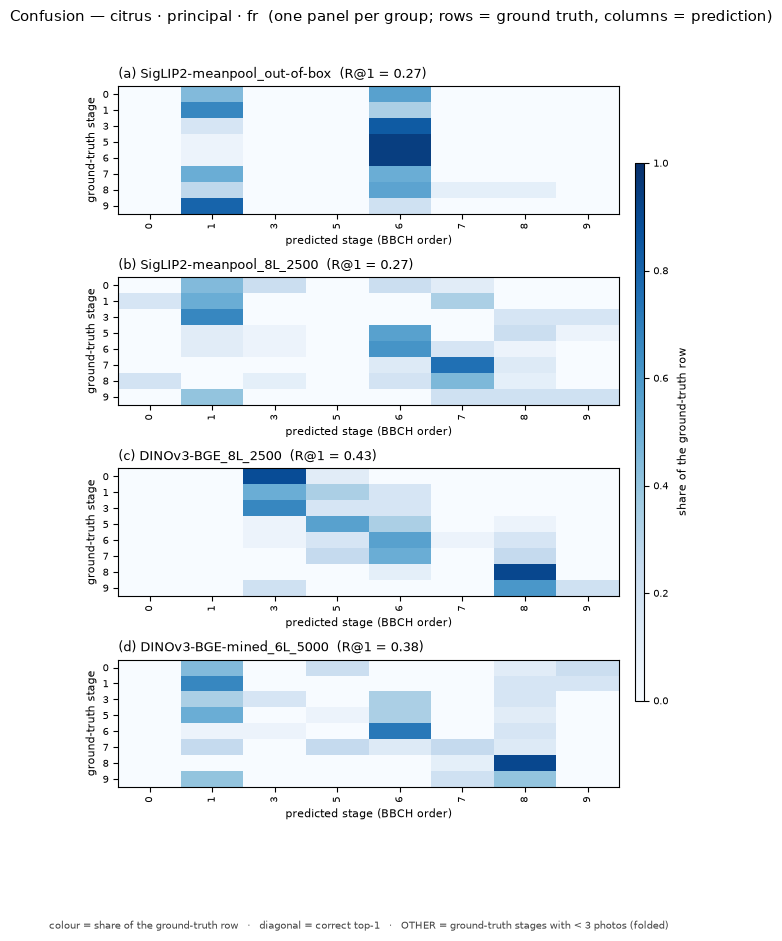

00:49:35 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_citrus_principal_en.pdf


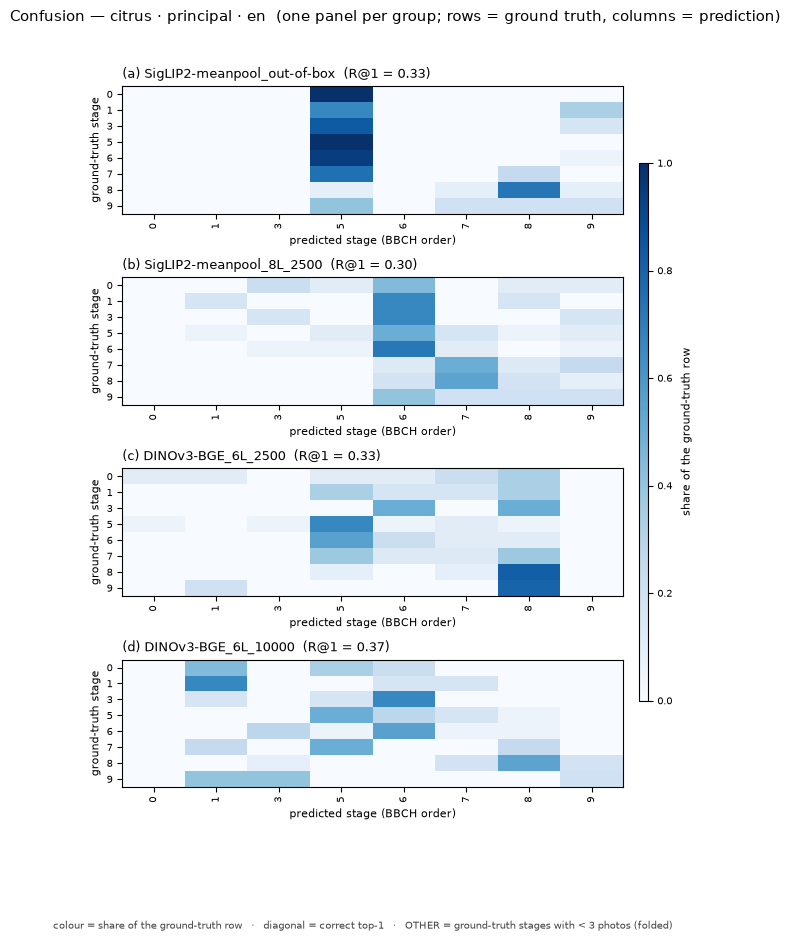

00:49:35 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_citrus_secondary_fr.pdf


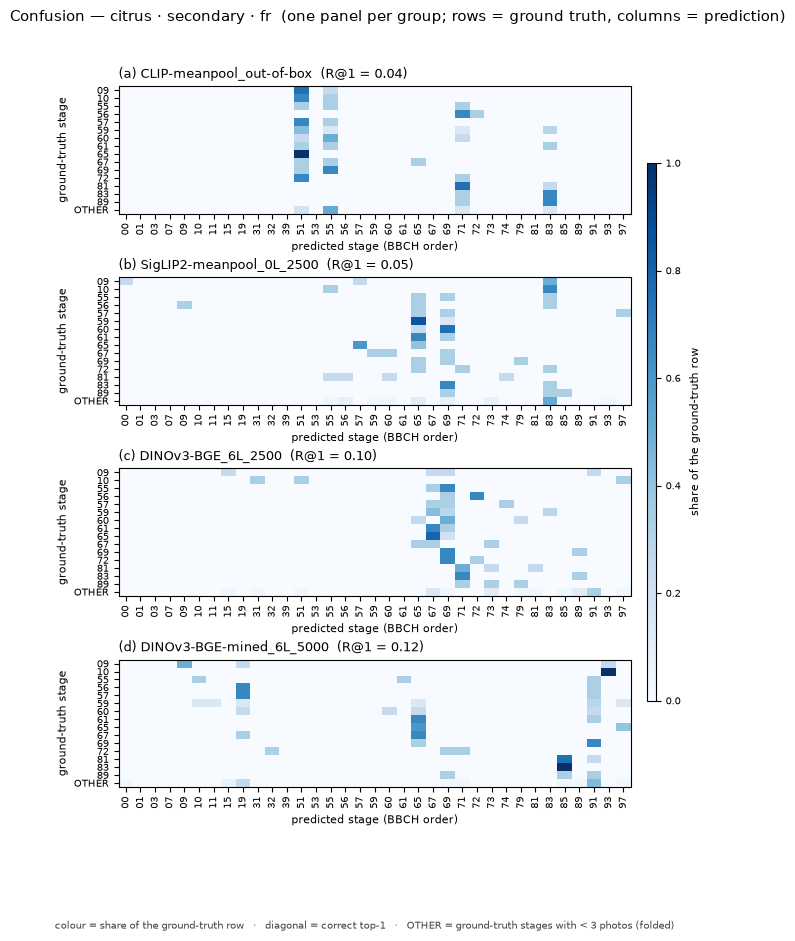

00:49:36 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_citrus_secondary_en.pdf


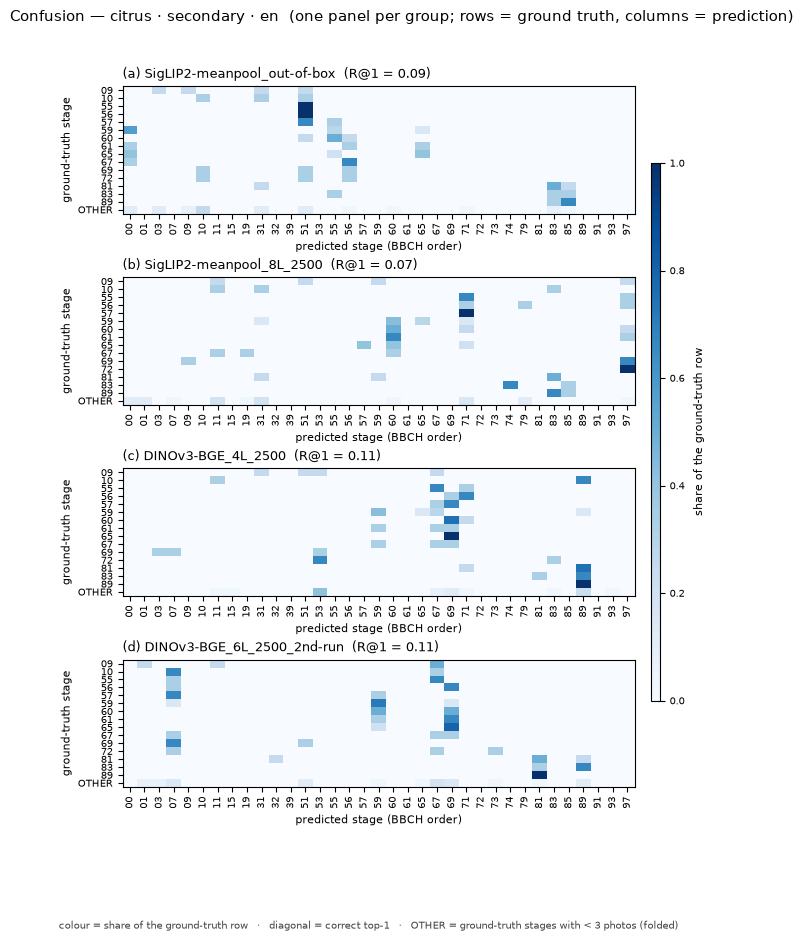

00:49:37 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_oilseedFlax_secondary_fr.pdf


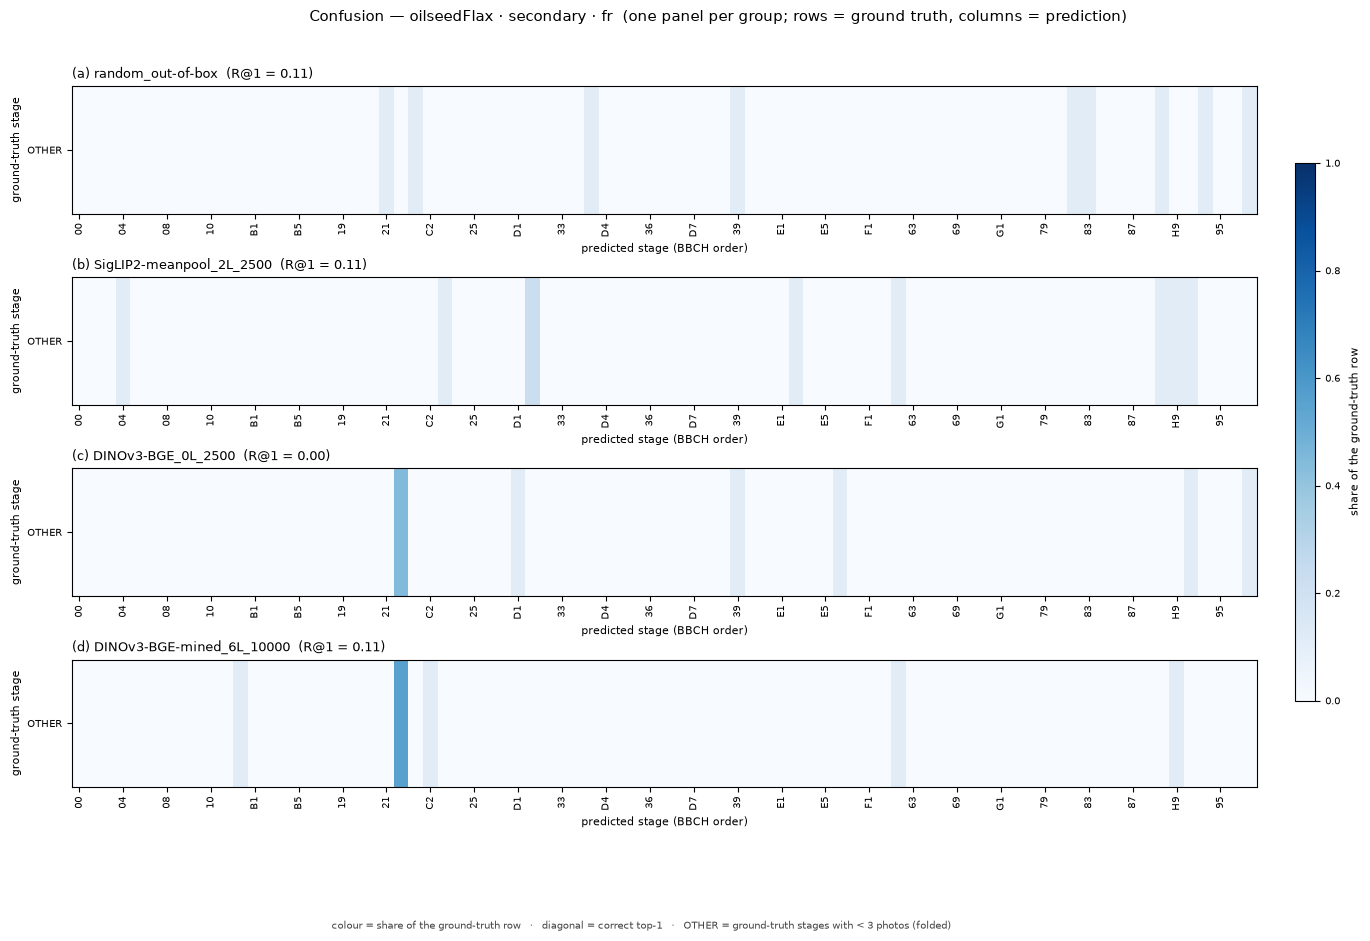

00:49:37 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_oilseedFlax_secondary_en.pdf


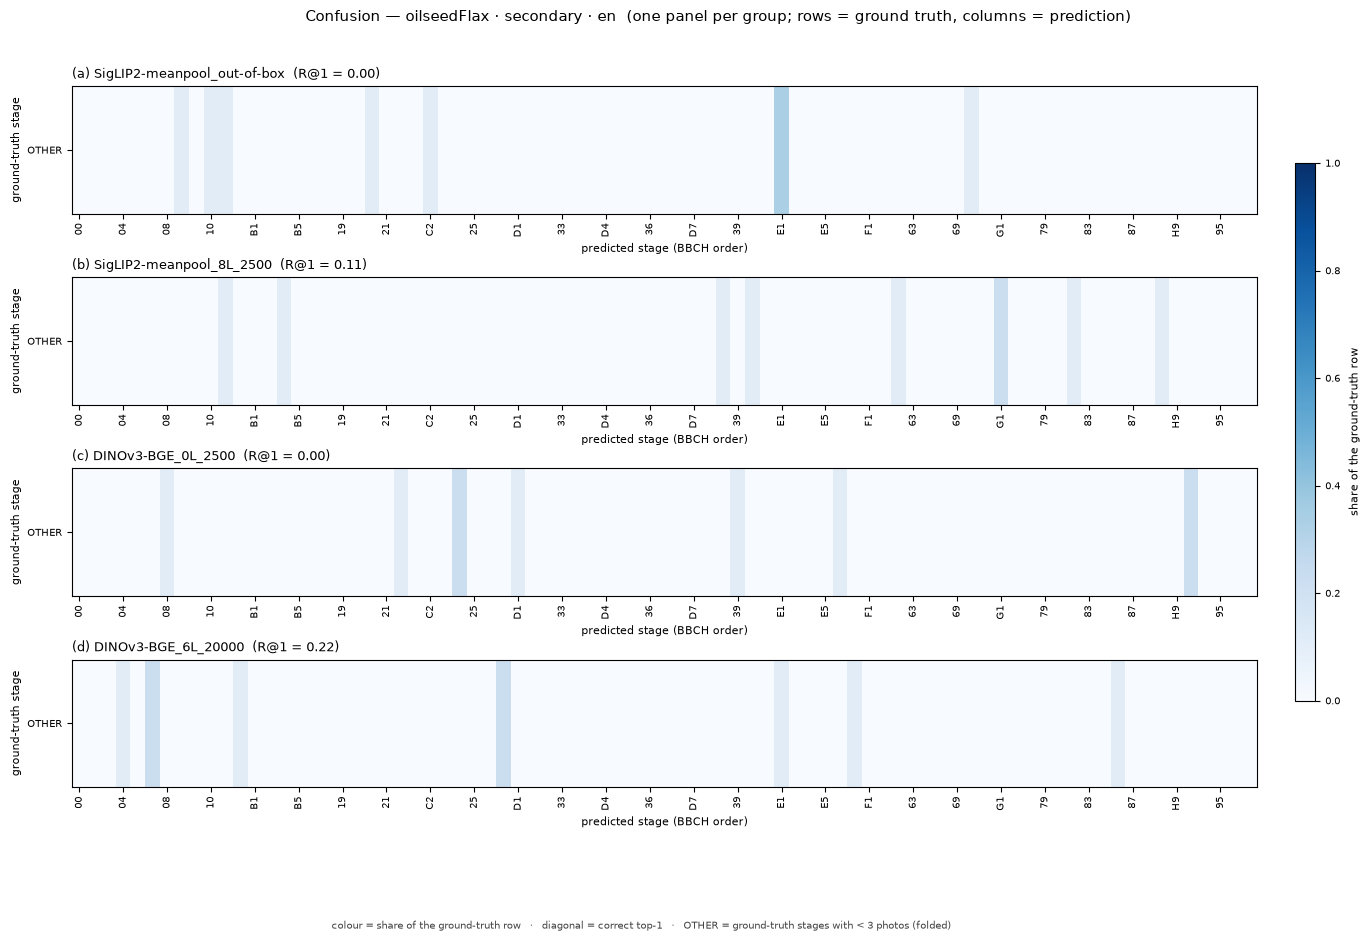

00:49:38 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_oilseedRape_secondary_fr.pdf


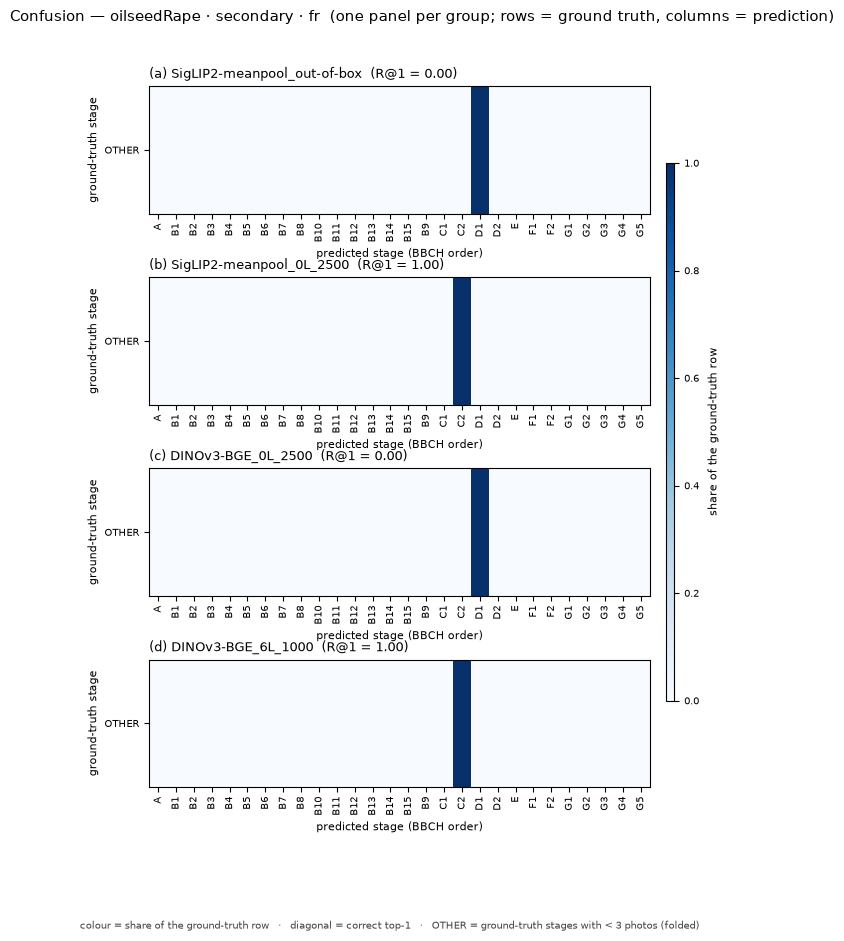

00:49:38 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion_oilseedRape_secondary_en.pdf


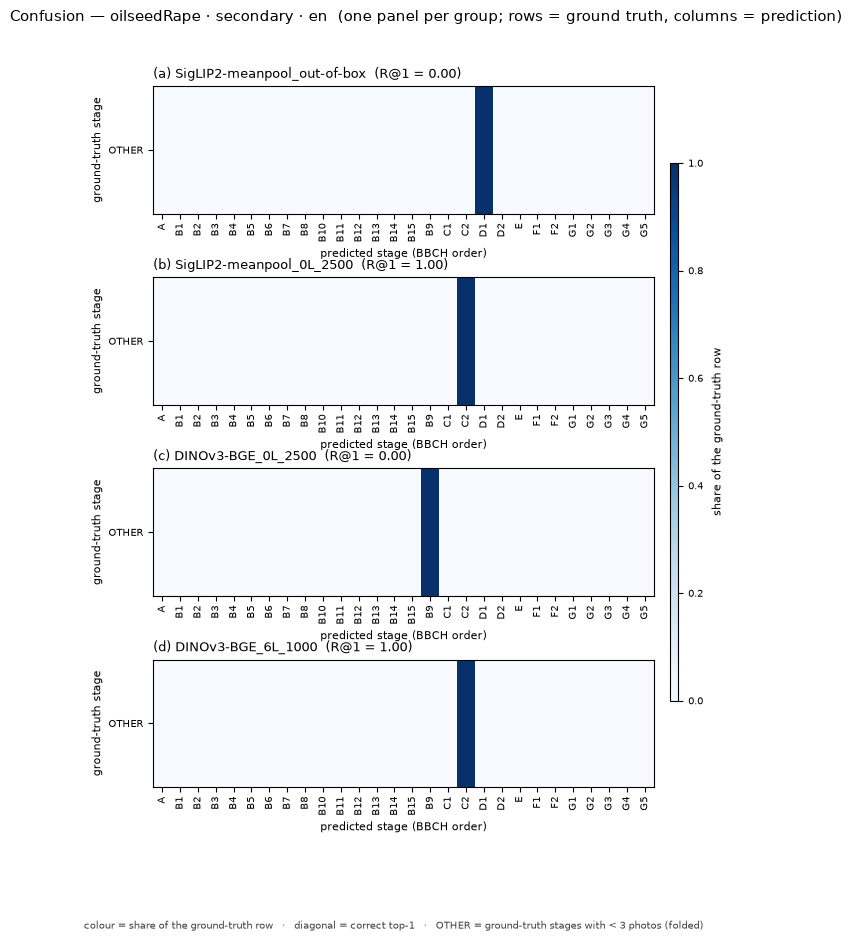

In [22]:
# --- finegrain_confusion_<crop>_<level>_<lang>.pdf  (8 heatmaps) ---------------
# One figure per (crop, level, lang): one panel per group, showing that group's best
# model by R@1 in the cell. Rows = ground truth (support < MIN_SUPPORT_FOR_HEATMAP folded
# into OTHER, identical row set for every model), columns = every pool stage,
# both ordinal-ordered.

def confusion_heatmap_panels(crop, level, lang):
    """(panels [(group, model)], kept gt rows, pool column order) for one cell."""
    cell = df_pred[(df_pred["crop_name"] == crop) & (df_pred["level"] == level)
                   & (df_pred["lang"] == lang)]
    r1 = cell.groupby("model_id")["is_correct"].mean()
    best = best_per_c0(r1, ascending=False)
    panels = [(k, best[k]) for k in C0_ORDER if k in best]

    order = sorted(pool_ids[(crop, level)],
                   key=lambda s: (ordinals[(crop, level)][s]["ordinal"], s))
    pooled = (pd.crosstab(cell["gt_id"], cell["pred_id"])
              .reindex(index=order, columns=order, fill_value=0))
    # per-model gt support (every model scores the same photos, verified in Section 3)
    support = pooled.sum(axis=1) / cell["model_id"].nunique()
    kept = support[support >= MIN_SUPPORT_FOR_HEATMAP].index.tolist()
    return panels, kept, order


def fold_rows(counts, kept):
    """Fold gt rows below the support threshold into OTHER (plot only)."""
    folded = counts.loc[kept]
    other = counts.drop(index=kept).sum(axis=0)
    if other.sum() > 0:
        folded.loc["OTHER"] = other
    return folded


for (crop, level) in EVALUATED_PAIRS:
    for lang in LANGUAGES:
        panels, kept, order = confusion_heatmap_panels(crop, level, lang)
        cell = df_pred[(df_pred["crop_name"] == crop) & (df_pred["level"] == level)
                       & (df_pred["lang"] == lang)]
        r1 = cell.groupby("model_id")["is_correct"].mean()

        # thin the column ticks on large pools so the stage ids stay legible
        col_step = max(1, int(np.ceil(len(order) / 40)))
        col_ticks = list(range(0, len(order), col_step))

        npanels = len(panels)
        fig, axes = plt.subplots(npanels, 1,
                                 figsize=(max(6.5, 0.19 * len(order)),
                                          max(6.0, 2.4 * npanels)),
                                 squeeze=False)
        im = None
        for ax, (key, model_id) in zip(axes.ravel(), panels):
            sub = cell[cell["model_id"] == model_id]
            counts = (pd.crosstab(sub["gt_id"], sub["pred_id"])
                      .reindex(index=order, columns=order, fill_value=0))
            counts = fold_rows(counts, kept)   # kept rows + OTHER from the rest
            rn = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0)
            im = ax.imshow(rn.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
            ax.set_xticks(col_ticks)
            ax.set_xticklabels([order[j] for j in col_ticks], rotation=90, fontsize=7)
            ax.set_yticks(range(len(counts.index)))
            ax.set_yticklabels(counts.index, fontsize=7)
            ax.set_xlabel("predicted stage (BBCH order)", fontsize=8)
            ax.set_ylabel("ground-truth stage", fontsize=8)
            ax.set_title(f"({key}) {model_label(model_id)}  "
                         f"(R@1 = {r1[model_id]:.2f})",
                         fontsize=9, loc="left")

        fig.subplots_adjust(left=0.08, right=0.85, top=0.90, bottom=0.17,
                            hspace=0.50)
        cax = fig.add_axes([0.875, 0.26, 0.013, 0.56])
        cb = fig.colorbar(im, cax=cax)
        cb.set_label("share of the ground-truth row", fontsize=8, labelpad=6)
        cb.ax.tick_params(labelsize=7)
        # caption: fixed text under the panels, so it never collides with the axis labels
        fig.text(0.45, 0.02,
                 "colour = share of the ground-truth row   ·   diagonal = correct top-1   ·   "
                 f"OTHER = ground-truth stages with < {MIN_SUPPORT_FOR_HEATMAP} photos (folded)",
                 ha="center", va="bottom", fontsize=7, color="#444444")
        fig.suptitle(f"Confusion — {crop} · {level} · {lang}  "
                     f"(one panel per group; rows = ground truth, "
                     f"columns = prediction)", fontsize=11)
        save_fig(fig, f"finegrain_confusion_{crop}_{level}_{lang}.pdf")
        plt.show()


## Section 10 — Persist results

All outputs in `figures/`, plain UTF-8, `index=False`, columns in a fixed order:

| file | content |
|---|---|
| `finegrain_predictions.csv` | one row per `(model, crop, level, lang, photo)` — the raw evidence |
| `finegrain_confusion.csv` | long format `model_id, crop_name, level, lang, gt_id, pred_id, count, row_rate` |
| `finegrain_ordinal_summary.csv` | per `(model, crop, level, lang)`: N, MAE, median, within-Δ, bias, Spearman, chance baselines |
| `finegrain_principal_consistency.csv` | per `(model, crop, lang)`: N, coherence, chance, level agreement |
| `finegrain_summary.csv` | the headline table: one row per `(model, level, lang)`, micro-averaged over crops |

`finegrain_c0_groups.csv` maps every internal `model_id` to its `model_label`
(`[architecture]_[unfrozen blocks]_[train size]`), which is what the figures display.

The headline summary micro-averages the photo-level metrics directly (top-1, off-by-one,
MAE, within-Δ, signed bias), photo-weights the chance baselines, and macro-averages the
per-cell quantities that have no per-photo meaning (confusion entropy, Spearman ρ).
`level_agreement` is computed only for `PRINCIPAL_CROPS` photos and is reported on the
`secondary` rows of the summary.


In [23]:
# --- finegrain_summary.csv (headline table) ----------------------------------
# PRED_CSV_COLS is defined (and the annotated predictions are written) in Section 5.

summary_rows = []
for model_id in MODEL_IDS:
    for level in ("principal", "secondary"):
        for lang in LANGUAGES:
            sub = df_pred[(df_pred["model_id"] == model_id)
                          & (df_pred["level"] == level) & (df_pred["lang"] == lang)]
            if sub.empty:
                continue
            cells = df_ordinal[(df_ordinal["model_id"] == model_id)
                               & (df_ordinal["level"] == level)
                               & (df_ordinal["lang"] == lang)]
            cm = df_confusion_metrics[(df_confusion_metrics["model_id"] == model_id)
                                      & (df_confusion_metrics["level"] == level)
                                      & (df_confusion_metrics["lang"] == lang)]
            w = cells["N"].to_numpy(dtype=float)

            def wavg(col, table=cells):
                v = table[col].to_numpy(dtype=float)
                ok = np.isfinite(v)
                ww, vv = w[ok], v[ok]
                return float((vv * ww).sum() / ww.sum()) if ww.sum() else np.nan

            row = {"model_id": model_id, "level": level, "lang": lang,
                   "N": int(len(sub)),
                   "top1_accuracy": float(sub["is_correct"].mean()),
                   "chance_accuracy": float((1.0 / sub["n_candidates"].to_numpy(dtype=float)).mean()),
                   "off_by_one_rate": float(sub["off_by_one"].mean()),
                   "mae": float(sub["ordinal_distance"].mean()),
                   "median_distance": float(sub["ordinal_distance"].median()),
                   "within_2": float((sub["ordinal_distance"] <= 2).mean()),
                   "chance_mae": wavg("chance_mae"),
                   "chance_within_2": wavg("chance_within_2"),
                   "signed_bias": float(sub["signed_distance"].mean()),
                   "spearman_rho_macro": float(cells["spearman_rho"].mean(skipna=True)),
                   "confusion_entropy_macro": wavg("confusion_entropy", cm),
                   }
            if level == "secondary":
                # coherence is defined for photos scored at secondary (micro over crops)
                row["coherence"] = float(sub["principal_match"].mean())
                pc_cells = df_pc[(df_pc["model_id"] == model_id) & (df_pc["lang"] == lang)]
                pw = pc_cells["N"].to_numpy(dtype=float)
                row["chance_coherence"] = float(
                    (pc_cells["chance_coherence"].to_numpy(dtype=float) * pw).sum() / pw.sum())
                la = pc_cells[pc_cells["crop_name"] == "citrus"]
                row["level_agreement"] = float(la["level_agreement"].iloc[0])
                row["chance_agreement"] = float(la["chance_agreement"].iloc[0])
            else:
                row["coherence"] = np.nan
                row["chance_coherence"] = np.nan
                row["level_agreement"] = np.nan
                row["chance_agreement"] = np.nan
            summary_rows.append(row)

SUMMARY_COLS = ["model_id", "level", "lang", "N", "top1_accuracy", "chance_accuracy",
                "off_by_one_rate", "mae", "median_distance", "within_2", "chance_mae",
                "chance_within_2", "signed_bias", "spearman_rho_macro",
                "confusion_entropy_macro", "coherence", "chance_coherence",
                "level_agreement", "chance_agreement"]
df_summary = pd.DataFrame(summary_rows)[SUMMARY_COLS]

# --- write all five CSVs and display them next to their paths -----------------
outputs = [
    ("finegrain_predictions.csv",
     df_pred[PRED_CSV_COLS].sort_values(["model_id", "crop_name", "level", "lang", "photo_name"])),
    ("finegrain_confusion.csv",
     df_confusion_long[["model_id", "crop_name", "level", "lang", "gt_id", "pred_id",
                        "count", "row_rate"]]),
    ("finegrain_ordinal_summary.csv", df_ordinal),
    ("finegrain_principal_consistency.csv", df_pc),
    ("finegrain_summary.csv", df_summary),
]
for name, frame in outputs:
    save_table(frame, name, preview=3)

# --- expected sizes (plan verification V5) -------------------------------------
# Derive the expected row counts from the model set and the evaluated scope, so the
# checks follow the 30-checkpoint configuration instead of hard-coding an old run.
n_secondary_crops = sum(1 for c in CROP_KIND if is_evaluated(c, "secondary"))
assert len(df_confusion_metrics) == len(MODEL_IDS) * len(EVALUATED_PAIRS) * len(LANGUAGES)
assert len(df_ordinal) == len(df_confusion_metrics)
assert len(df_pc) == len(MODEL_IDS) * len(LANGUAGES) * n_secondary_crops
assert len(df_summary) == len(MODEL_IDS) * 2 * len(LANGUAGES)
assert len(df_pred) == int(df_confusion_metrics["N"].sum())
assert set(df_summary["model_id"]) == set(MODEL_IDS)
print(f"Row-count checks OK: predictions {len(df_pred)}, "
      f"ordinal summary {len(df_ordinal)}, "
      f"principal consistency {len(df_pc)}, summary {len(df_summary)}.")


00:49:39 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_predictions.csv (10320 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_predictions.csv (10320 rows, 17 columns)


,model_id,crop_name,level,lang,photo_name,gt_id,pred_id,gt_ordinal,pred_ordinal,signed_distance,ordinal_distance,off_by_one,rank,n_candidates,gt_principal,pred_principal,principal_match
0,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_00_1.jpg,0,0,0.0,0.0,0.0,0.0,False,1,8,0,0,True
1,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_01_1.jpg,0,0,0.0,0.0,0.0,0.0,False,1,8,0,0,True
2,26_zs_clip_meanpool,citrus,principal,en,citrus#photo_citrus_bbch_03_1.jpg,0,5,0.0,5.0,5.0,5.0,False,2,8,0,5,False


00:49:39 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion.csv (6241 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_confusion.csv (6241 rows, 8 columns)


,model_id,crop_name,level,lang,gt_id,pred_id,count,row_rate
0,26_zs_siglip2_meanpool,citrus,principal,fr,0,1,4,0.444444
1,26_zs_siglip2_meanpool,citrus,principal,fr,0,6,5,0.555556
2,26_zs_siglip2_meanpool,citrus,principal,fr,1,1,4,0.666667


... (6 outputs left out)

00:49:39 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_summary.csv (120 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_summary.csv (120 rows, 19 columns)


,model_id,level,lang,N,top1_accuracy,chance_accuracy,off_by_one_rate,mae,median_distance,within_2,chance_mae,chance_within_2,signed_bias,spearman_rho_macro,confusion_entropy_macro,coherence,chance_coherence,level_agreement,chance_agreement
0,26_zs_siglip2_meanpool,principal,fr,81,0.271605,0.125000,0.333333,2.271605,1.0,0.679012,3.242284,0.458333,-0.395062,0.004906,0.564707,NaN,NaN,NaN,NaN
1,26_zs_siglip2_meanpool,principal,en,81,0.333333,0.125000,0.333333,1.765432,1.0,0.753086,3.242284,0.458333,0.679012,0.441195,0.510215,NaN,NaN,NaN,NaN
2,26_zs_siglip2_meanpool,secondary,fr,91,0.021978,0.027045,0.065934,36.175824,34.0,0.054945,31.558919,0.079661,-21.516484,0.190478,0.387153,0.241758,0.135338,0.135802,0.070416


Row-count checks OK: predictions 10320, ordinal summary 240, principal consistency 180, summary 120.


00:49:40 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_summary_heatmap.pdf


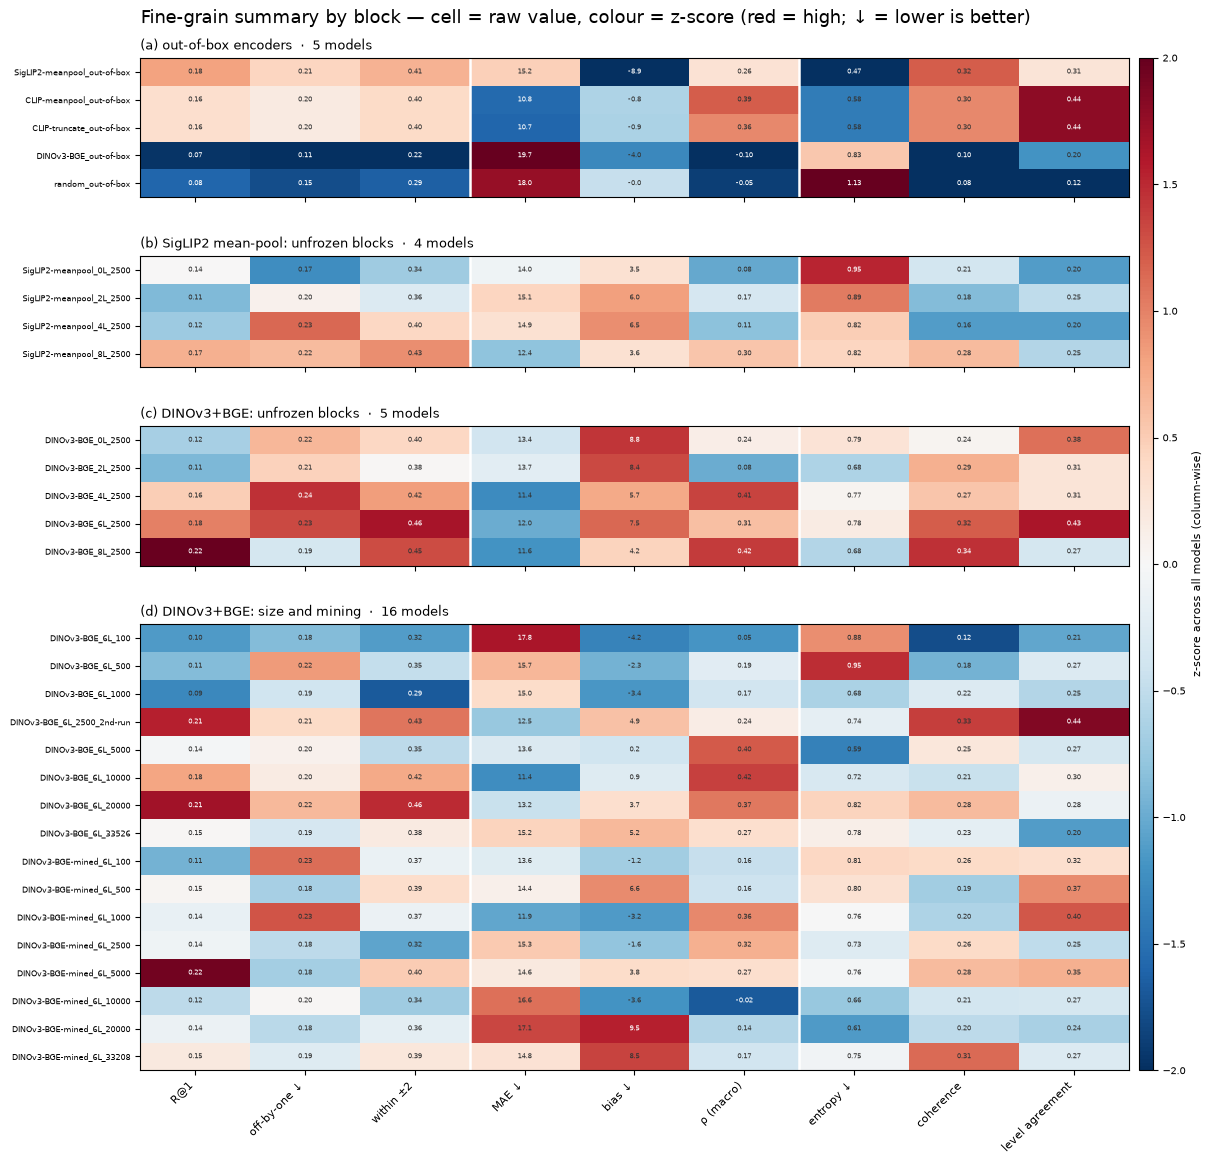

In [24]:
# --- finegrain_summary_heatmap.pdf ---------------------------------------------
# Models x metrics, z-scored per metric column, one panel per C0 group. Panel heights are
# proportional to the group size, so every (model, metric) cell is the same size; the raw
# value is printed in each cell. Arrows mark the metrics where lower is better.
SUMMARY_METRICS = ["top1_accuracy", "off_by_one_rate", "within_2",
                   "mae", "signed_bias", "spearman_rho_macro",
                   "confusion_entropy_macro", "coherence", "level_agreement"]
LOWER_IS_BETTER = {"off_by_one_rate", "mae", "signed_bias", "confusion_entropy_macro"}
COL_LABEL = {
    "top1_accuracy": "R@1",
    "off_by_one_rate": "off-by-one ↓",
    "within_2": "within ±2",
    "mae": "MAE ↓",
    "signed_bias": "bias ↓",
    "spearman_rho_macro": "ρ (macro)",
    "confusion_entropy_macro": "entropy ↓",
    "coherence": "coherence",
    "level_agreement": "level agreement",
}
VALUE_FMT = {m: "{:.1f}" for m in ("mae", "signed_bias")}

agg = df_summary.groupby("model_id")[SUMMARY_METRICS].mean()
z = (agg - agg.mean()) / agg.std(ddof=0)

COUNTS = {k: len([m for m in C0_MEMBERS[k] if m in agg.index]) for k in C0_ORDER}
CELL_H, N_METRICS = 0.34, len(SUMMARY_METRICS)
fig_h = CELL_H * sum(COUNTS.values()) + 2.0
fig = plt.figure(figsize=(13.5, fig_h))
gs = fig.add_gridspec(len(C0_ORDER), 2,
                      width_ratios=[70, 1],
                      height_ratios=[COUNTS[k] for k in C0_ORDER],
                      hspace=0.28, wspace=0.02,
                      left=0.17, right=0.92, top=0.94, bottom=0.11)

im = None
for i, key in enumerate(C0_ORDER):
    ax = fig.add_subplot(gs[i, 0])
    members = [m for m in C0_MEMBERS[key] if m in agg.index]
    sub_z = z.loc[members, SUMMARY_METRICS]
    sub_raw = agg.loc[members, SUMMARY_METRICS]
    im = ax.imshow(sub_z.to_numpy(dtype=float), cmap="RdBu_r", vmin=-2, vmax=2,
                   aspect="auto")
    # metric blocks: ranking | distance | structure
    for x in (2.5, 5.5):
        ax.axvline(x, color="white", linewidth=1.8)
    ax.set_yticks(range(len(members)))
    ax.set_yticklabels([model_label(m) for m in members], fontsize=6)
    ax.set_xticks(range(N_METRICS))
    if i == len(C0_ORDER) - 1:
        ax.set_xticklabels([COL_LABEL[m] for m in SUMMARY_METRICS],
                           rotation=45, ha="right", fontsize=8)
    else:
        ax.set_xticklabels([])
    ax.set_title(f"({key}) {C0_SHORT[key]}  ·  {len(members)} models",
                 fontsize=9, loc="left")
    for r in range(len(members)):
        for c_i, metric in enumerate(SUMMARY_METRICS):
            value = sub_raw.iloc[r, c_i]
            if not np.isfinite(value):
                continue
            ax.text(c_i, r, VALUE_FMT.get(metric, "{:.2f}").format(value),
                    ha="center", va="center", fontsize=4.8,
                    color="white" if abs(sub_z.iloc[r, c_i]) > 1.4 else "#333333")

cax = fig.add_subplot(gs[:, 1])
cb = fig.colorbar(im, cax=cax)
cb.set_label("z-score across all models (column-wise)", fontsize=8)
cb.ax.tick_params(labelsize=7)
fig.suptitle("Fine-grain summary by block — cell = raw value, colour = z-score "
             "(red = high; ↓ = lower is better)", fontsize=13)
save_fig(fig, "finegrain_summary_heatmap.pdf")
plt.show()



## Findings (auto-generated)

The cell below prints the headline numbers per `(level, lang)`: the best models by exact
stage (R@1) and by phenological proximity (ordinal MAE), the chance references, and the
largest confusions of the overall best model. **There is no single headline metric**:
R@1 measures exact stage identity, while ordinal MAE / within-±2 measure phenological
proximity — they rank models differently, and the findings below report both.


In [25]:
print(f"Models: {len(MODEL_IDS)} | evaluated (crop, level, lang) cells: "
      f"{len(EVALUATED_PAIRS) * len(LANGUAGES)}")
for (level, lang) in GROUPS:
    sub = df_pred[(df_pred["level"] == level) & (df_pred["lang"] == lang)]
    top1 = sub.groupby("model_id")["is_correct"].mean().sort_values(ascending=False)
    mae = sub.groupby("model_id")["ordinal_distance"].mean().sort_values()
    chance_mae = micro_cells(df_ordinal, "chance_mae", level, lang)
    print(f"\n=== {level} · {lang} (N={len(sub)}) ===")
    print(f"  best R@1 : {model_label(top1.index[0])}  ({top1.iloc[0]:.3f})")
    print(f"  best MAE : {model_label(mae.index[0])}  ({mae.iloc[0]:.2f} BBCH units; "
          f"chance = {chance_mae:.2f})")
    print(f"  within ±2 (best-MAE model): "
          f"{(sub[sub['model_id'] == mae.index[0]]['ordinal_distance'] <= 2).mean():.3f}")

# biggest confusions of the overall best model (citrus secondary, French)
best_model = (df_pred.groupby("model_id")["is_correct"].mean()
              .sort_values(ascending=False).index[0])
sub = df_pred[(df_pred["model_id"] == best_model) & (df_pred["crop_name"] == "citrus")
              & (df_pred["level"] == "secondary") & (df_pred["lang"] == "fr")]
pairs = (sub[~sub["is_correct"]].groupby(["gt_id", "pred_id"]).size()
         .sort_values(ascending=False).head(8))
print(f"\n=== Largest confusions — {model_label(best_model)}, citrus secondary · fr ===")
save_table(pairs.rename("count").to_frame().reset_index(),
           "finegrain_top_confusions.csv", preview=None)

Models: 30 | evaluated (crop, level, lang) cells: 8

=== principal · fr (N=2430) ===
  best R@1 : DINOv3-BGE_8L_2500  (0.432)
  best MAE : DINOv3-BGE_8L_2500  (1.21 BBCH units; chance = 3.24)
  within ±2 (best-MAE model): 0.802

=== principal · en (N=2430) ===
  best R@1 : DINOv3-BGE_6L_10000  (0.370)
  best MAE : SigLIP2-meanpool_out-of-box  (1.77 BBCH units; chance = 3.24)
  within ±2 (best-MAE model): 0.753

=== secondary · fr (N=2730) ===
  best R@1 : DINOv3-BGE-mined_6L_5000  (0.121)
  best MAE : DINOv3-BGE_6L_10000  (19.64 BBCH units; chance = 31.56)
  within ±2 (best-MAE model): 0.154

=== secondary · en (N=2730) ===
  best R@1 : DINOv3-BGE_4L_2500  (0.099)
  best MAE : DINOv3-BGE_4L_2500  (17.62 BBCH units; chance = 31.56)
  within ±2 (best-MAE model): 0.176

=== Largest confusions — DINOv3-BGE_8L_2500, citrus secondary · fr ===
00:49:40 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_top_confusions.csv (8 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_top_confusions.csv (8 rows, 3 columns)


,gt_id,pred_id,count
0,56,69,3
1,59,69,3
2,65,69,3
3,57,65,2
4,55,51,2
5,60,69,2
6,59,65,2
7,59,67,2


PosixPath('/mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/finegrain_top_confusions.csv')

### Findings (from the run)

**Naming is hard; localising is easy.** Best R@1 is 0.432 / 0.370 at principal (fr / en)
but only 0.121 / 0.099 at secondary. For the best fine-tuned models the secondary ordinal
MAE is 19.6 / 17.6 BBCH units against an exact chance of 31.6, and at best 21 / 24 % of
top-1s fall within ±2 units of the truth (different models realise those two maxima). The
models find the phenological neighbourhood far more often than the exact stage.

**Predictions lean late.** The best French secondary model by R@1
(`DINOv3-BGE-mined_6L_5000`) has a signed bias of +7.8 BBCH units, and the R@1 winner is
not the MAE winner: `DINOv3-BGE_6L_10000` has the lowest French secondary MAE (19.6).
Part of the ranking skill comes from a shifted mapping, not from a better ordering.

**Hierarchy holds only partly.** On citrus secondary, hierarchical coherence is 0.25
median (max 0.41) against a 0.135 chance share, but level agreement between the
principal-task top-1 and the secondary prediction's principal digit is 0.28 median
(0.53 max). Agreement is not a substitute for correctness.

**R@1 and MAE rank models differently.** French principal is won by
`DINOv3-BGE_8L_2500` on both metrics (0.432 R@1, 1.21 MAE), but French secondary R@1
favours `DINOv3-BGE-mined_6L_5000` (0.121) while `DINOv3-BGE_6L_10000` has the lowest MAE
(19.6). Report both, never one alone.

**Controls behave.** The out-of-box SigLIP2 mean-pool encoder wins principal-en MAE
(1.77) against every fine-tuned model, while the out-of-box DINOv3+BGE encoder is far
behind (3.37) because its towers are not aligned. Fine-tuning helps the secondary level
much more than the principal one.
